# Diffusion conditionnelle et volatilité

L'étude complète, des données au verdict. Ce qui ne demande pas de GPU est **recalculé** ; les résultats des modèles de
diffusion, dont l'entraînement demande un GPU et plusieurs heures, sont **relus** dans `app/donnees/` et contrôlés.

| § | Étape | Contenu | Nature |
|---|---|---|---|
| 0 bis | Protocole | chaîne de traitement, information utilisée, prévention des fuites, critères | — |
| 1 | Données et analyse exploratoire | statistiques, volatilité, queues, autocorrélations, dépendance entre marchés | recalculé |
| 2 | Référence GARCH | GARCH-*t* et GJR-*t* par maximum de vraisemblance ; CRPS sur le test | recalculé |
| 3 | EDS de bruitage | diffusion à variance préservée ; calendriers *quad* et *cosinus* | recalculé |
| 4 | Score et Tweedie | vérification Monte-Carlo de la formule de Tweedie | recalculé |
| 5 | Biais de dispersion | déficit de variance, DDIM, Euler-Maruyama : forme fermée, récurrence, simulation | recalculé |
| 6 | Règles de score | CRPS, estimateur équitable, sensibilité à l'échelle | recalculé |
| 7 | Panel I, modèle A | prévision, Diebold-Mariano, régimes, VaR, imputation, ablation | relu et contrôlé |
| 8 | Panel II, modèle B | prévision, imputation, interprétabilité, vérification sur Exchange Rate, loi jointe | relu et recalculé |
| 9 | Coût de calcul | opérations par scénario, hypothèses vérifiées, temps mesurés | recalculé et relu |
| 10 | Synthèse | résultats et écart entre les modèles A et B | — |

**Exécution**, depuis la racine du dépôt :

```bash
pip install -r notebooks/requirements.txt
jupyter lab notebooks/diffusion_volatilite_A_a_Z.ipynb
```

Durée : une à deux minutes sur processeur.

## 0. Préparation

In [1]:
import json, math, sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize
from scipy.special import beta as Beta, gammaln

warnings.filterwarnings("ignore")

ROOT = Path.cwd().resolve()
if not (ROOT / "app").exists():          # lancé depuis notebooks/
    ROOT = ROOT.parent
APP, DATA = ROOT / "app", ROOT / "app" / "donnees"
sys.path.insert(0, str(APP))
import theorie as T                       # résultats analytiques partagés avec le démonstrateur

pd.set_option("display.precision", 4)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (11, 4), "figure.dpi": 110, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
BLUE, ORANGE, GREEN, GREY, PURPLE = "#2a78d6", "#d95926", "#199e70", "#8a8984", "#7a6fd6"
rng = np.random.default_rng(2026)

js = lambda name: json.loads((DATA / f"{name}.json").read_text(encoding="utf-8"))
print("Données lues dans :", DATA.relative_to(ROOT))

Données lues dans : app/donnees


## 0 bis. Protocole

Chaîne de traitement d'un cas (rapport, figure 8.1).

| Phase | Étape | Contenu |
|---|---|---|
| **Apprentissage** (une fois) | masquage | fenêtres de l'apprentissage ; cases cachées tirées au hasard (fin, points, blocs, prix) |
| | bruitage, régression | seules les cibles sont bruitées ; erreur quadratique sur $v$ (A) ou $\varepsilon$ (B) |
| | validation | arrêt, schéma, nombre de pas, $\lambda$ des EWMA ; puis gel |
| **Génération** (chaque cas du test) | masque | fixé, commun à toutes les méthodes |
| | processus inverse | du bruit aux cibles, réseau gelé : 20 pas (A), 50 pas (B) |
| | scénarios | $M$ tirages (99 pour A) ; projection sur la somme connue si des prix manquent |
| **Évaluation** | références | mêmes cas, même information, même $M$ |
| | critères | CRPS, couverture, VaR (Kupiec, Christoffersen), energy score ; Diebold-Mariano (I), bootstrap (II) |

**Information utilisée en imputation** (rapport, tableau 3.1).

| Méthode | passé | après le trou | même jour | somme | queues épaisses |
|---|:-:|:-:|:-:|:-:|:-:|
| Interpolation linéaire | | | | ● | |
| Pont EWMA | ● | | | ● | |
| Pont à volatilité locale | | ● | | ● | |
| Lisseur GJR-*t* | ● | ● | | ● | ● |
| EWMA multivarié sous contrainte | ● | | ● | ● | |
| Modèle A | ●ᵃ | ● | | ● | ● |
| Modèle B | | ● | ● | (●)ᵇ | ● |

a : volatilité EWMA à l'entrée de la fenêtre uniquement. b : par projection a posteriori, non évaluée.

**Prévention des fuites** (rapport, section 8.2).

| Règle | Contenu |
|---|---|
| Estimation | une seule, sur l'apprentissage ; paramètres gelés, filtres avancés sans réestimation |
| Réglage | arrêt, schéma, nombre de pas, $\lambda$ : sur la validation |
| Normalisations | moyennes, écarts-types, $\bar\sigma$, seuil du twCRPS, matrice $R$ : apprentissage seul ; l'échelle d'une fenêtre ne dépend que de ses cases observées |
| Frontières | panel II : $L+H$ jours retirés entre périodes ; aucune fenêtre à cheval |
| Comparaison | mêmes cas, masques, information et nombre de scénarios pour toutes les méthodes |
| Réserve | certaines analyses décidées après une première lecture du test ; aucun chiffre modifié |

**Critères** (rapport, annexe A.5).

| Terme | Sens de lecture | Définition |
|---|---|---|
| Scénario | — | trajectoire simulée ; $M$ scénarios décrivent la loi prédictive |
| CRPS | plus bas = mieux | écart entre loi prédictive et réalisation ; pénalise biais et dispersion excessive |
| Couverture à 90 % | proche de 90 % | fréquence des réalisations dans l'intervalle ; en dessous, risque sous-estimé |
| VaR à 1 % | 1 dépassement sur 100 | Kupiec : fréquence des dépassements ; Christoffersen : indépendance |
| Diebold-Mariano | négatif = diffusion meilleure | écart de score / erreur-type ; significatif à 5 % au-delà de ±1,96 |
| Intervalle bootstrap | exclut 0 = établi | blocs mensuels et entraînements rééchantillonnés |
| Energy score | plus bas = mieux | CRPS multivarié |
| Volatilité réalisée | CRPS plus bas = mieux | évalue le regroupement des grandes variations dans une trajectoire |
| Non établi | ≠ égal | différence non démontrée |
| NFE | — | évaluations du réseau par scénario ; coût proportionnel |

## 1. Données et analyse exploratoire

* **Panel I** : S&P 500, Euro Stoxx 50, FTSE 100, avril 2007 – novembre 2026 ; **modèle A** (univarié).
* **Panel II** : huit actifs de quatre classes, 2010 – 2026 ; **modèle B** (multivarié, de type CSDI).

Log-rendements quotidiens en % : $r_t = 100\,\log(P_t/P_{t-1})$.

| Période | Panel I | Panel II |
|---|---|---|
| Apprentissage | avril 2007 – décembre 2018 | janvier 2010 – 1ᵉʳ octobre 2021 |
| Validation | 2019 – 2020 | janvier 2022 – septembre 2023 |
| Test | janvier 2021 – novembre 2026 | janvier 2024 – octobre 2026 |

In [2]:
def returns_I(code):
    raw = pd.read_csv(DATA / "panel_I" / f"{code}.csv", skiprows=3, header=None, usecols=[0, 1],
                      names=["date", "close"], parse_dates=["date"], index_col="date")
    p = raw["close"].astype(float).dropna()
    return p, 100 * np.log(p).diff().dropna()

INDICES = {"SP500": "S&P 500", "STOXX50E": "Euro Stoxx 50", "FTSE100": "FTSE 100"}
PRIX, R = {}, {}
for k in INDICES:
    PRIX[k], R[k] = returns_I(k)

def describe(r):
    return pd.Series({"début": r.index[0].date(), "fin": r.index[-1].date(), "n": len(r), "moyenne %": r.mean(),
                      "écart-type %": r.std(), "asymétrie": stats.skew(r), "kurtosis": stats.kurtosis(r, fisher=False),
                      "min %": r.min(), "max %": r.max()})

pd.DataFrame({INDICES[k]: describe(R[k]) for k in INDICES})

,S&P 500,Euro Stoxx 50,FTSE 100
début,2007-01-04,2007-04-02,2007-01-03
fin,2026-11-06,2026-11-09,2026-11-09
n,4993,4916,5015
moyenne %,0.033,0.0082,0.0106
écart-type %,1.2397,1.3683,1.1171
asymétrie,-0.4779,-0.3027,-0.4295
kurtosis,15.5338,10.7316,13.3929
min %,-12.7652,-13.2405,-11.5117
max %,10.9572,10.4376,9.3842


Kurtosis de 10,7 à 15,5 (3 pour une loi normale) : queues épaisses. Moyenne quotidienne de quelques centièmes de %, écart-type
d'environ 1 % : l'information prévisible porte sur l'échelle de la loi, pas sur sa moyenne.

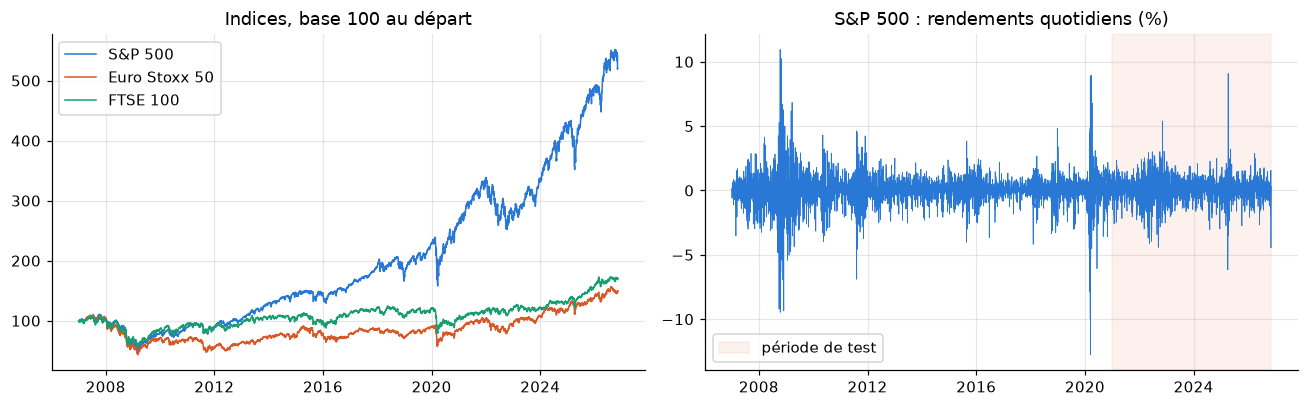

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for k, c in zip(INDICES, [BLUE, ORANGE, GREEN]):
    p = PRIX[k]; ax[0].plot(p / p.iloc[0] * 100, color=c, lw=1, label=INDICES[k])
ax[0].set_title("Indices, base 100 au départ"); ax[0].legend()
r = R["SP500"]
ax[1].plot(r, color=BLUE, lw=.5)
ax[1].axvspan(pd.Timestamp("2021-01-01"), r.index[-1], color=ORANGE, alpha=.08, label="période de test")
ax[1].set_title("S&P 500 : rendements quotidiens (%)"); ax[1].legend()
plt.tight_layout(); plt.show()

### Faits stylisés

1. Autocorrélation des rendements quasi nulle, autocorrélation de $|r_t|$ forte et lente : regroupement de volatilité.
2. Effet de levier : $\operatorname{corr}(r_t, |r_{t+1}|) < 0$.

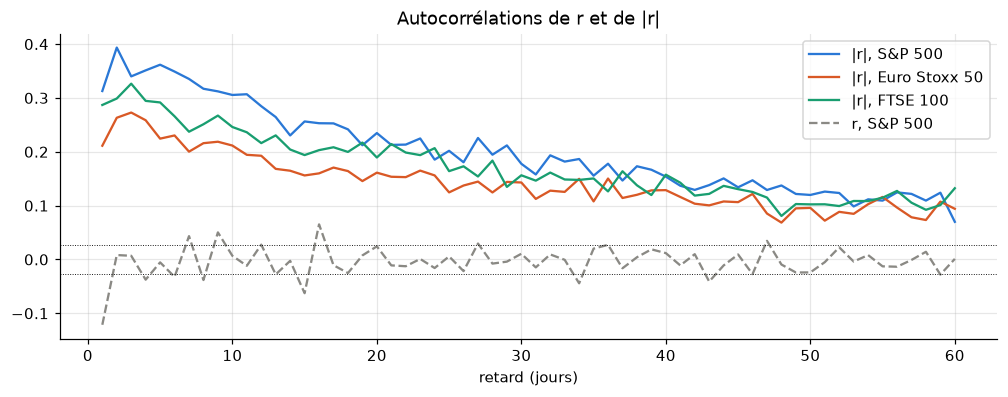

Effet de levier corr(r_t, |r_t+1|) : {'S&P 500': np.float64(-0.125), 'Euro Stoxx 50': np.float64(-0.129), 'FTSE 100': np.float64(-0.122)}


In [4]:
def acf(x, nlags):
    x = np.asarray(x) - np.mean(x); d = np.dot(x, x)
    return np.array([np.dot(x[:-h], x[h:]) / d for h in range(1, nlags + 1)])

L = 60
fig, ax = plt.subplots(figsize=(11, 3.6))
for k, c in zip(INDICES, [BLUE, ORANGE, GREEN]):
    ax.plot(range(1, L + 1), acf(np.abs(R[k]), L), color=c, label=f"|r|, {INDICES[k]}")
ax.plot(range(1, L + 1), acf(R["SP500"], L), color=GREY, ls="--", label="r, S&P 500")
ax.axhline(1.96 / np.sqrt(len(R["SP500"])), color="k", lw=.6, ls=":"); ax.axhline(-1.96 / np.sqrt(len(R["SP500"])), color="k", lw=.6, ls=":")
ax.set_xlabel("retard (jours)"); ax.set_title("Autocorrélations de r et de |r|"); ax.legend()
plt.show()

lev = {INDICES[k]: np.corrcoef(R[k].values[:-1], np.abs(R[k].values[1:]))[0, 1] for k in INDICES}
print("Effet de levier corr(r_t, |r_t+1|) :", {k: round(v, 3) for k, v in lev.items()})

### Volatilité et queues

Volatilité sur 21 jours, annualisée, et fréquence des grands écarts standardisés comparée à la loi normale.

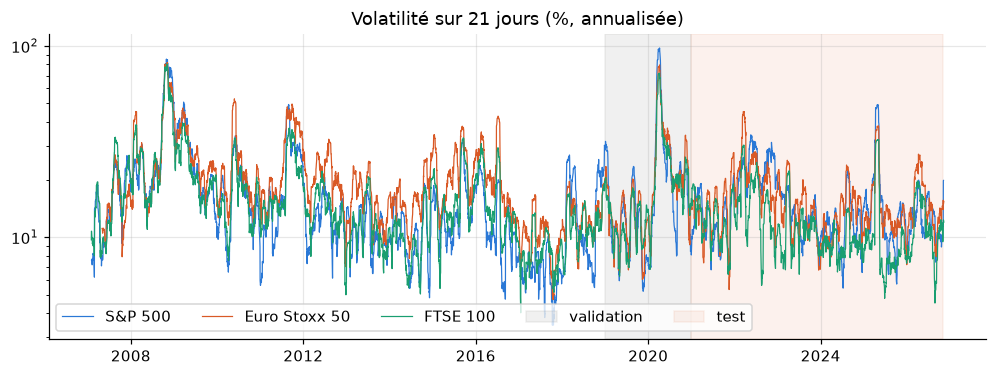

Rapport max / min de la volatilité glissante : {'S&P 500': 28.1, 'Euro Stoxx 50': 17.3, 'FTSE 100': 20.0}


,P(|z| > 3),P(|z| > 4),P(|z| > 5)
S&P 500,1.68e-02,7.61e-03,4.01e-03
Euro Stoxx 50,1.59e-02,5.90e-03,2.64e-03
FTSE 100,1.58e-02,6.78e-03,2.59e-03
loi normale,2.70e-03,6.33e-05,5.73e-07


In [5]:
fig, ax = plt.subplots(figsize=(11, 3.6))
ratios = {}
for k, c in zip(INDICES, [BLUE, ORANGE, GREEN]):
    v = R[k].rolling(21).std() * np.sqrt(252)
    ratios[INDICES[k]] = v.max() / v.min()
    ax.plot(v, color=c, lw=.8, label=INDICES[k])
ax.axvspan(pd.Timestamp("2019-01-01"), pd.Timestamp("2020-12-31"), color=GREY, alpha=.12, label="validation")
ax.axvspan(pd.Timestamp("2021-01-01"), R["SP500"].index[-1], color=ORANGE, alpha=.08, label="test")
ax.set_yscale("log"); ax.set_title("Volatilité sur 21 jours (%, annualisée)"); ax.legend(ncol=5)
plt.show()
print("Rapport max / min de la volatilité glissante :", {k: round(float(v), 1) for k, v in ratios.items()})

rows = {}
for k in INDICES:
    z = (R[k] - R[k].mean()) / R[k].std()
    rows[INDICES[k]] = {f"P(|z| > {a})": (np.abs(z) > a).mean() for a in (3, 4, 5)}
tails = pd.DataFrame(rows).T
tails.loc["loi normale"] = [2 * stats.norm.sf(a) for a in (3, 4, 5)]
tails.style.format("{:.2e}")

### Panel II : dépendance entre marchés

Rendements réduits par la moyenne et l'écart-type de l'apprentissage. Corrélations du même jour, sur les jours où les deux
marchés cotent.

Panel II : 4388 jours × 8 actifs, 2010-01-04 → 2026-10-30
Valeurs manquantes par actif (calendriers de cotation différents) : {'^GSPC': 310, '^STOXX50E': 280, '^FTSE': 241, '^N225': 482, 'GC=F': 310, 'BZ=F': 364, 'EURUSD=X': 15, 'IEF': 310}


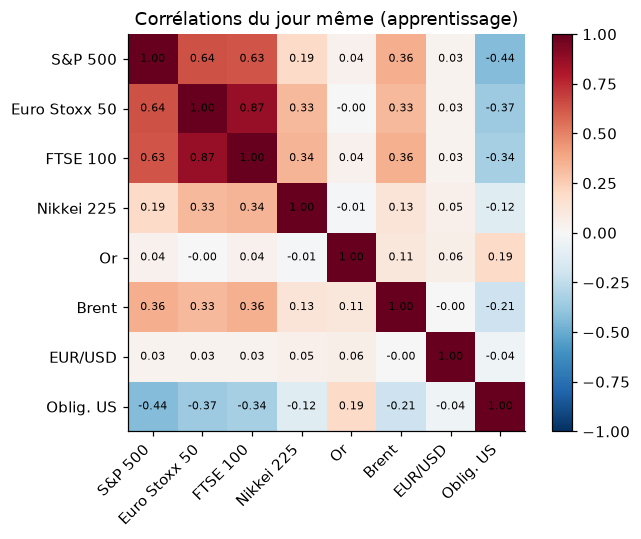

In [6]:
TICKERS_II = ["^GSPC", "^STOXX50E", "^FTSE", "^N225", "GC=F", "BZ=F", "EURUSD=X", "IEF"]
ASSETS_II = ["S&P 500", "Euro Stoxx 50", "FTSE 100", "Nikkei 225", "Or", "Brent", "EUR/USD", "Oblig. US"]
df2 = pd.read_csv(DATA / "panel_II" / "panel_returns.csv", index_col=0, parse_dates=True)[TICKERS_II]
train2 = df2.loc[:"2021-10-01"]
Z2 = (df2 - train2.mean()) / train2.std()
print(f"Panel II : {df2.shape[0]} jours × {df2.shape[1]} actifs, {df2.index[0].date()} → {df2.index[-1].date()}")
print("Valeurs manquantes par actif (calendriers de cotation différents) :", df2.isna().sum().to_dict())

C = train2.corr().values
fig, ax = plt.subplots(figsize=(6.2, 5))
im = ax.imshow(C, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(8), ASSETS_II, rotation=45, ha="right"); ax.set_yticks(range(8), ASSETS_II); ax.grid(False)
for i in range(8):
    for j in range(8):
        ax.text(j, i, f"{C[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, fraction=.046); ax.set_title("Corrélations du jour même (apprentissage)"); plt.tight_layout(); plt.show()

Dépendance d'un jour sur l'autre : corrélation entre le rendement d'un actif le jour $t$ et celui d'un autre le jour $t+1$, sur l'apprentissage.

In [7]:
same, lagged = [], []
for i in range(8):
    for j in range(8):
        if i != j:
            lagged.append(abs(train2[TICKERS_II[i]].corr(train2[TICKERS_II[j]].shift(-1))))
            if i < j:
                same.append(abs(train2[TICKERS_II[i]].corr(train2[TICKERS_II[j]])))
print(f"Apprentissage. Corrélation absolue, même jour : moyenne {np.mean(same):.2f} ; décalée d'un jour : médiane {np.median(lagged):.2f}")
print(f"S&P 500 (t) → Nikkei 225 (t+1) : {train2['^GSPC'].corr(train2['^N225'].shift(-1)):.2f} ; "
      f"même jour : {train2['^GSPC'].corr(train2['^N225']):.2f}")

Apprentissage. Corrélation absolue, même jour : moyenne 0.22 ; décalée d'un jour : médiane 0.03
S&P 500 (t) → Nikkei 225 (t+1) : 0.44 ; même jour : 0.19


## 2. Référence : GARCH-*t* et GJR-*t*

$$
r_t = \mu + \sigma_t z_t,\qquad z_t \sim t_\nu \text{ réduite},\qquad
\sigma_t^2 = \omega + \big(\alpha + \gamma\,\mathbb 1_{\{r_{t-1}<\mu\}}\big)(r_{t-1}-\mu)^2 + \beta\,\sigma_{t-1}^2 .
$$

$\gamma = 0$ : GARCH-*t* ; $\gamma > 0$ : GJR-*t* (effet de levier). Persistance $\phi = \alpha + \gamma/2 + \beta$,
demi-vie $\log(1/2) / \log \phi$ jours.

Estimation par maximum de vraisemblance sur l'apprentissage du S&P 500, comparée aux paramètres du projet.

In [8]:
def unpack(theta, gjr):
    if gjr:
        mu, om, a, g, b, nu = theta
    else:
        mu, om, a, b, nu = theta; g = 0.0
    return mu, om, a, g, b, nu

def sigma2_path(r, mu, om, a, g, b, s2_0):
    e = r - mu; s2 = np.empty(len(r) + 1); s2[0] = s2_0
    for t in range(len(r)):
        s2[t + 1] = om + (a + g * (e[t] < 0)) * e[t] ** 2 + b * s2[t]
    return s2                                  # s2[t] = variance de r[t] ; s2[-1] = prévision du lendemain

def student_logpdf_std(z, nu):                 # t de Student réduite (variance 1)
    c = gammaln((nu + 1) / 2) - gammaln(nu / 2) - 0.5 * np.log(np.pi * (nu - 2))
    return c - (nu + 1) / 2 * np.log1p(z ** 2 / (nu - 2))

def negloglik(theta, r, gjr):
    mu, om, a, g, b, nu = unpack(theta, gjr)
    if om <= 0 or a < 0 or g < 0 or b < 0 or a + g / 2 + b >= 1.0 + 1e-6 or nu <= 2.05:
        return 1e10
    s2 = sigma2_path(r, mu, om, a, g, b, np.var(r))[:-1]
    return -np.sum(student_logpdf_std((r - mu) / np.sqrt(s2), nu) - 0.5 * np.log(s2))

def fit(r, gjr):
    x0 = [0.05, 0.02, 0.03, 0.12, 0.88, 6.0] if gjr else [0.05, 0.02, 0.10, 0.88, 6.0]
    bnds = ([(-1, 1), (1e-6, 1), (0, .5), (0, .8), (0, .9999), (2.1, 50)] if gjr
            else [(-1, 1), (1e-6, 1), (0, .5), (0, .9999), (2.1, 50)])
    res = minimize(negloglik, x0, args=(r, gjr), method="L-BFGS-B", bounds=bnds)
    mu, om, a, g, b, nu = unpack(res.x, gjr)
    phi = a + g / 2 + b
    k = len(res.x)
    return {"mu": mu, "omega": om, "alpha": a, "gamma": g, "beta": b, "nu": nu, "phi": phi,
            "demi-vie (j)": np.log(.5) / np.log(phi) if phi < 1 else np.inf,
            "log-vrais.": -res.fun, "AIC": 2 * res.fun + 2 * k}

r_sp = R["SP500"]; r_train = r_sp.loc[:"2018-12-31"].values
FIT = {"GARCH-t": fit(r_train, gjr=False), "GJR-t": fit(r_train, gjr=True)}
print(f"Apprentissage S&P 500 : {len(r_train)} jours")
pd.DataFrame(FIT).T

Apprentissage S&P 500 : 3019 jours


,mu,omega,alpha,gamma,beta,nu,phi,demi-vie (j),log-vrais.,AIC
GARCH-t,0.0820,0.0162,0.1341,0.0000,0.8647,4.8988,0.9988,569.3091,-3989.7426,7989.4851
GJR-t,0.0529,0.0192,0.0000,0.2545,0.8630,5.2242,0.9902,70.4499,-3935.2898,7882.5796


In [9]:
ref = pd.read_csv(DATA / "panel_I" / "garch_table.csv")
ref.columns = [c.replace("$", "").replace("\\", "") for c in ref.columns]
ref = ref.apply(lambda s: s.astype(str).str.replace("\\", "", regex=False).str.replace("$", "", regex=False))
print("Paramètres retenus dans le projet (erreurs-types entre parenthèses) :")
ref[ref["Index"].str.startswith("S&P")]

Paramètres retenus dans le projet (erreurs-types entre parenthèses) :


,Index,Model,mu,omega,alpha,gamma,beta,nu,phi,Half-life,Log-lik.,AIC
0,S&P 500,GARCH-t,0.080 (0.012),0.014 (0.005),0.131 (0.017),--,0.869 (0.017),5.219 (0.488),1.0,infty,-3924.6,7859.2
1,S&P 500,GJR-t,0.053 (0.012),0.019 (0.004),0.000 (0.015),0.247 (0.038),0.866 (0.018),5.557 (0.584),0.9892,64,-3869.7,7751.3


**Contrôle.** Paramètres retrouvés : GARCH-*t*, $\alpha \approx 0{,}13$, $\beta \approx 0{,}87$, $\nu \approx 5{,}2$,
persistance égale à 1 ; GJR-*t*, $\alpha \approx 0$, $\gamma \approx 0{,}25$ : la réaction aux chocs passe entièrement par
les baisses. Gain de log-vraisemblance du GJR : plus de 50 points pour un paramètre.

### Prévision à un jour et CRPS sur le test

Paramètres gelés à la fin de l'apprentissage ; filtre avancé jour par jour. CRPS de la loi de Student en forme fermée
(§ 6).

In [10]:
def crps_student(y, mu, scale, nu):
    # CRPS d'une loi mu + scale * t_nu (t standard, non réduite) : forme fermée de Gneiting et Raftery
    z = (y - mu) / scale
    F, f = stats.t.cdf(z, nu), stats.t.pdf(z, nu)
    c = 2 * np.sqrt(nu) * Beta(.5, nu - .5) / ((nu - 1) * Beta(.5, nu / 2) ** 2)
    return scale * (z * (2 * F - 1) + 2 * f * (nu + z ** 2) / (nu - 1) - c)

test_mask = r_sp.index >= "2021-01-01"
rows = {}
for name, p in FIT.items():
    s2 = sigma2_path(r_sp.values, p["mu"], p["omega"], p["alpha"], p["gamma"], p["beta"], np.var(r_train))[:-1]
    sd = np.sqrt(s2)[test_mask]; y = r_sp.values[test_mask]; nu = p["nu"]
    scale = sd * np.sqrt((nu - 2) / nu)
    q = stats.t.ppf(.95, nu) * scale
    rows[name] = {"CRPS h=1 (recalculé)": crps_student(y, p["mu"], scale, nu).mean(),
                  "couverture 90 %": np.mean(np.abs(y - p["mu"]) <= q), "n jours": len(y)}
    if name == "GJR-t":
        vol_gjr = pd.Series(np.sqrt(s2), index=r_sp.index)

ft = pd.read_csv(DATA / "panel_I" / "forecast_table.csv")
for name in rows:
    rows[name]["CRPS h=1 (projet)"] = ft.query("index=='SP500' and model==@name")["CRPS_h1"].item()
pd.DataFrame(rows).T

,CRPS h=1 (recalculé),couverture 90 %,n jours,CRPS h=1 (projet)
GARCH-t,0.5386,0.8904,1469.0,0.5368
GJR-t,0.5351,0.8965,1469.0,0.5340


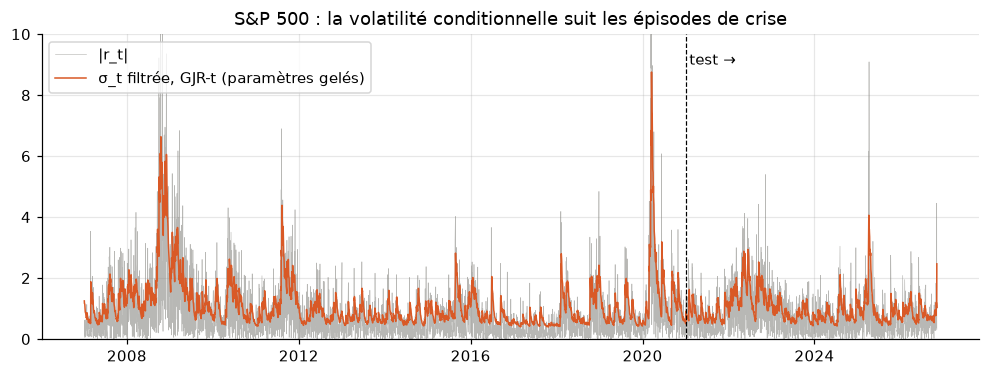

In [11]:
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(np.abs(r_sp), color=GREY, lw=.4, alpha=.6, label="|r_t|")
ax.plot(vol_gjr, color=ORANGE, lw=1, label="σ_t filtrée, GJR-t (paramètres gelés)")
ax.axvline(pd.Timestamp("2021-01-01"), color="k", lw=.8, ls="--"); ax.text(pd.Timestamp("2021-02-01"), 9, "test →")
ax.set_ylim(0, 10); ax.set_title("S&P 500 : la volatilité conditionnelle suit les épisodes de crise"); ax.legend(); plt.show()

CRPS proche de celui du projet ; l'écart résiduel vient de l'initialisation du filtre et de l'optimiseur.

### Propriétés de la récurrence GJR

**Impact des nouvelles.** Depuis $\bar\sigma^2 = 1$, variance du lendemain
$\omega + \beta + (\alpha + \gamma\,\mathbb 1_{\varepsilon<0})\,\varepsilon^2$ : une baisse de 2 % ajoute $4\gamma$, une hausse $4\alpha$.

**Kurtosis d'un GARCH(1,1)** (proposition 3.3) : $\kappa = \kappa_z\,\dfrac{1-\phi^2}{1-\phi^2-(\kappa_z-1)\alpha^2}$.

**Invariance d'échelle** (proposition 3.5) : $c\,r_t$ suit un GJR de paramètre $c^2\omega$ ; les rendements standardisés
sont inchangés.

In [12]:
g = FIT["GJR-t"]
print(f"GJR-t estimé : une baisse de 2 % ajoute {4 * g['gamma']:.2f} à la variance du lendemain, une hausse {4 * g['alpha']:.2f}")

# Kurtosis : formule contre simulation (GARCH gaussien, φ = 0,97)
phi_k, kz = 0.97, 3.0
for a_ in (0.05, 0.10):
    th = kz * (1 - phi_k ** 2) / (1 - phi_k ** 2 - (kz - 1) * a_ ** 2)
    z = rng.standard_normal(1_000_000); s2, out = 1.0, np.empty(z.size)
    for t in range(z.size):
        out[t] = np.sqrt(s2) * z[t]; s2 = (1 - phi_k) + a_ * out[t] ** 2 + (phi_k - a_) * s2
    print(f"α = {a_:.2f} : kurtosis formule {th:.2f}, simulation {np.mean(out ** 4) / np.mean(out ** 2) ** 2:.2f}")

# Symétrie d'échelle : rendements standardisés identiques à l'arrondi machine près
cc, r_ = 3.0, r_sp.values[:500]
s_1 = sigma2_path(r_, g["mu"], g["omega"], g["alpha"], g["gamma"], g["beta"], 1.0)[:-1]
s_c = sigma2_path(cc * r_, cc * g["mu"], cc ** 2 * g["omega"], g["alpha"], g["gamma"], g["beta"], cc ** 2)[:-1]
print(f"Écart maximal entre r/σ et cr/(cσ) : {np.max(np.abs((r_ - g['mu']) / np.sqrt(s_1) - (cc * r_ - cc * g['mu']) / np.sqrt(s_c))):.1e}")

GJR-t estimé : une baisse de 2 % ajoute 1.02 à la variance du lendemain, une hausse 0.00


α = 0.05 : kurtosis formule 3.28, simulation 3.27


α = 0.10 : kurtosis formule 4.53, simulation 4.62
Écart maximal entre r/σ et cr/(cσ) : 1.8e-15


## 3. EDS de bruitage

EDS à variance préservée :

$$
\mathrm d x = -\tfrac12 \beta(t)\, x\,\mathrm dt + \sqrt{\beta(t)}\,\mathrm dW_t
\quad\Longrightarrow\quad
x_k = \sqrt{\bar\alpha_k}\,x_0 + \sqrt{1-\bar\alpha_k}\,\varepsilon,\qquad \varepsilon\sim\mathcal N(0, I).
$$

Calendriers $(\bar\alpha_k)$ : **quad** ($K = 50$, $\sqrt{\beta_k}$ linéaire), modèle B ; **cosinus** ($K = 200$), modèle A.

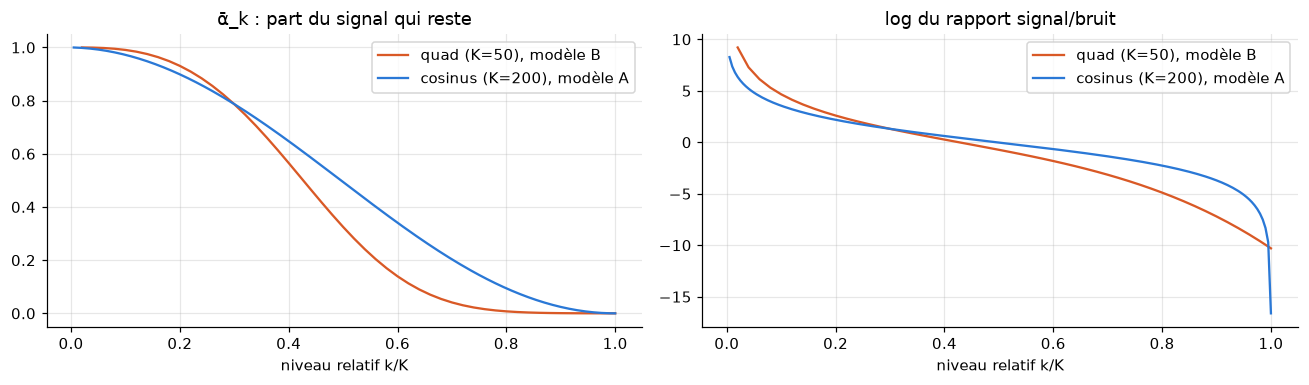

quad : ᾱ_1 = 0.99990, ᾱ_K = 3.35e-05   |   cosinus : ᾱ_1 = 0.99975, ᾱ_K = 6.07e-08


In [13]:
ab_q, ab_c = T.quad_schedule(), T.cosine_schedule()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for ab, lab, c in [(ab_q, "quad (K=50), modèle B", ORANGE), (ab_c, "cosinus (K=200), modèle A", BLUE)]:
    u = np.arange(1, len(ab) + 1) / len(ab)
    ax[0].plot(u, ab, color=c, label=lab)
    ax[1].plot(u, np.log(ab / (1 - ab)), color=c, label=lab)
ax[0].set_title("ᾱ_k : part du signal qui reste"); ax[1].set_title("log du rapport signal/bruit")
for a in ax: a.set_xlabel("niveau relatif k/K"); a.legend()
plt.tight_layout(); plt.show()
print(f"quad : ᾱ_1 = {ab_q[0]:.5f}, ᾱ_K = {ab_q[-1]:.2e}   |   cosinus : ᾱ_1 = {ab_c[0]:.5f}, ᾱ_K = {ab_c[-1]:.2e}")

Bruitage des rendements réduits du S&P 500 : les queues épaisses disparaissent et la loi converge vers $\mathcal N(0,1)$.

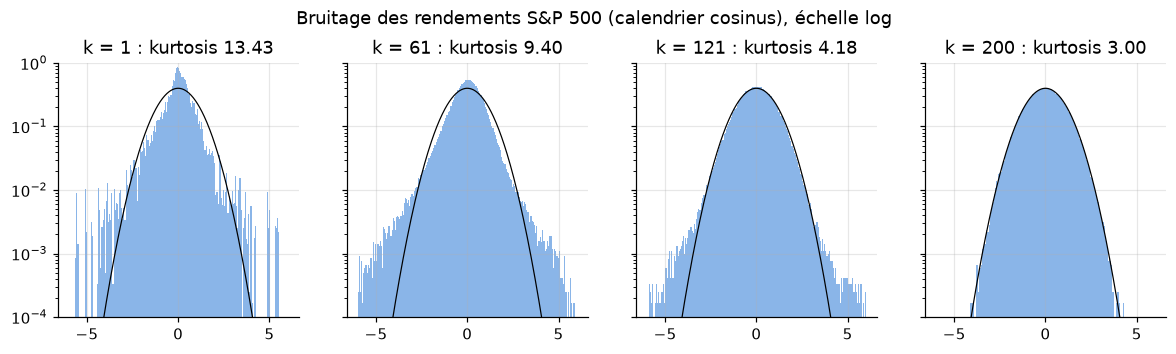

In [14]:
x0 = ((r_train - r_train.mean()) / r_train.std())
x0 = rng.choice(x0, 200_000)
fig, ax = plt.subplots(1, 4, figsize=(13, 3), sharey=True)
grid_ = np.linspace(-6, 6, 400)
for a_, k in zip(ax, [0, 60, 120, 199]):
    a_k = ab_c[k]
    xk = np.sqrt(a_k) * x0 + np.sqrt(1 - a_k) * rng.standard_normal(x0.size)
    a_.hist(xk, bins=200, range=(-6, 6), density=True, color=BLUE, alpha=.55)
    a_.plot(grid_, stats.norm.pdf(grid_), color="k", lw=.8)
    a_.set_title(f"k = {k+1} : kurtosis {stats.kurtosis(xk, fisher=False):.2f}"); a_.set_yscale("log"); a_.set_ylim(1e-4, 1)
fig.suptitle("Bruitage des rendements S&P 500 (calendrier cosinus), échelle log", y=1.04); plt.show()

**Chaîne discrète et EDS** (corollaire 4.2). Euler-Maruyama à pas fin depuis $x_0$, comparé à la loi exacte
$\mathcal N(\sqrt{\bar\alpha_k}\,x_0,\ 1-\bar\alpha_k)$.

In [15]:
K_ = len(ab_q); B_ = np.concatenate([[0.0], -np.log(ab_q)]); sub = 40; x_start = -3.43
X = np.full(4000, x_start); m_, s_ = [x_start], [0.0]
for k in range(K_):
    b = B_[k + 1] - B_[k]
    for _ in range(sub):
        X = X - 0.5 * b * X / sub + np.sqrt(b / sub) * rng.standard_normal(X.size)
    m_.append(X.mean()); s_.append(X.std())
th_m, th_s = x_start * np.exp(-B_ / 2), np.sqrt(1 - np.exp(-B_))
print(f"Écart maximal, moyenne : {np.max(np.abs(np.array(m_) - th_m)):.3f} ; écart-type : {np.max(np.abs(np.array(s_) - th_s)):.3f}")

Écart maximal, moyenne : 0.022 ; écart-type : 0.028


## 4. Score et formule de Tweedie

Le processus inverse requiert le score $\nabla \log p_k(x)$, appris par moindres carrés via la formule de Tweedie :

$$
\mathbb E[x_0 \mid x_k = x] = \frac{x + (1-\bar\alpha_k)\,\nabla\log p_k(x)}{\sqrt{\bar\alpha_k}},
\qquad
\hat\varepsilon(x) = -\sqrt{1-\bar\alpha_k}\;\nabla\log p_k(x).
$$

$\varepsilon$, $x_0$ et la vitesse $v = \sqrt{\bar\alpha}\,\varepsilon - \sqrt{1-\bar\alpha}\,x_0$ sont des rotations du
couple $(x_0, \varepsilon)$. Le modèle A prédit $v$, le modèle B $\varepsilon$.

**Vérification.** Loi jouet à queues épaisses (mélange de deux gaussiennes, kurtosis 5,72) : moyenne conditionnelle
empirique, par tranches de $x_k$, contre Tweedie avec le score exact.

Loi jouet : variance 1.001, kurtosis 5.75 (théorie 5,72)


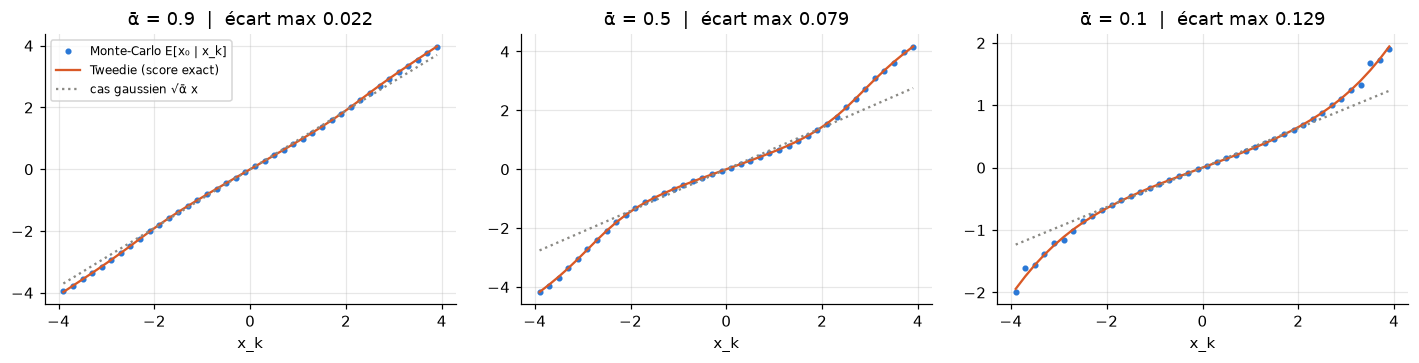

In [16]:
def mix_sample(n):
    comp = rng.random(n) < T.PI_MIX[1]
    return rng.standard_normal(n) * np.sqrt(np.where(comp, T.VAR_MIX[1], T.VAR_MIX[0]))

N = 2_000_000
x0m = mix_sample(N)
print(f"Loi jouet : variance {x0m.var():.3f}, kurtosis {stats.kurtosis(x0m, fisher=False):.2f} (théorie 5,72)")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for a_, a in zip(ax, [0.9, 0.5, 0.1]):
    xk = np.sqrt(a) * x0m + np.sqrt(1 - a) * rng.standard_normal(N)
    bins = np.linspace(-4, 4, 41); idx = np.digitize(xk, bins)
    cen = 0.5 * (bins[1:] + bins[:-1])
    emp = np.array([x0m[idx == i].mean() for i in range(1, len(bins))])
    tw = (cen - np.sqrt(1 - a) * T.mixture_eps(cen, a)) / np.sqrt(a)      # Tweedie avec le bruit optimal exact
    a_.plot(cen, emp, "o", ms=3, color=BLUE, label="Monte-Carlo E[x₀ | x_k]")
    a_.plot(cen, tw, color=ORANGE, label="Tweedie (score exact)")
    a_.plot(cen, np.sqrt(a) * cen, color=GREY, ls=":", label="cas gaussien √ᾱ x")
    a_.set_title(f"ᾱ = {a}  |  écart max {np.nanmax(np.abs(emp - tw)):.3f}"); a_.set_xlabel("x_k")
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

In [17]:
# Les trois paramétrisations sont des rotations : on retrouve (x0, ε) à partir de v et x_k
a = 0.37; x0_, e_ = rng.standard_normal(5), rng.standard_normal(5)
xk_ = np.sqrt(a) * x0_ + np.sqrt(1 - a) * e_
v_ = np.sqrt(a) * e_ - np.sqrt(1 - a) * x0_
print("x0 retrouvé depuis (x_k, v) :", np.allclose(np.sqrt(a) * xk_ - np.sqrt(1 - a) * v_, x0_))
print("ε  retrouvé depuis (x_k, v) :", np.allclose(np.sqrt(1 - a) * xk_ + np.sqrt(a) * v_, e_))

x0 retrouvé depuis (x_k, v) : True
ε  retrouvé depuis (x_k, v) : True


## 5. Biais de dispersion

Même avec un débruiteur exact, la discrétisation du processus inverse déforme la loi. Cas gaussien : $x_0\sim\mathcal N(0,1)$ ;
chaque pas est affine, la sortie est $\mathcal N(0, v_0)$ et $v_0$ se calcule par récurrence.

**Théorème 5.5.** Le schéma ancestral à variance $\tilde\beta$ sur les $K$ niveaux vérifie

$$
1 - v_0 = \beta_1 + \sum_{k=2}^{K} \frac{(\bar\alpha_{k-1}\beta_k)^2}{1-\bar\alpha_k}.
$$

Trois vérifications indépendantes : formule, récurrence exacte, simulation.

In [18]:
rows = {}
for name, ab in [("quad (modèle B)", ab_q), ("cosinus (modèle A)", ab_c)]:
    closed = T.deficit_closed_form(ab)
    rec = 1 - T.gaussian_output_std(ab, "ddpm") ** 2
    x, _, _ = T.sample(ab, "ddpm", None, T.gaussian_eps, rng.standard_normal(400_000), rng)
    sd = np.sqrt(1 - closed)
    rows[name] = {"1−v₀ forme fermée": closed, "1−v₀ récurrence": rec, "1−v₀ Monte-Carlo": 1 - x.var(),
                  "écart-type de sortie": sd, "couverture réelle d'un IC 90 %": T.coverage90(sd)}
DEF = pd.DataFrame(rows).T
DEF

,1−v₀ forme fermée,1−v₀ récurrence,1−v₀ Monte-Carlo,écart-type de sortie,couverture réelle d'un IC 90 %
quad (modèle B),0.1131,0.1131,0.1127,0.9418,0.8786
cosinus (modèle A),0.0235,0.0235,0.0193,0.9882,0.8959


Formule, récurrence et simulation coïncident. Déficit : **11,3 %** (quad, modèle B), **2,4 %** (cosinus, modèle A) ; le
calendrier seul change le déficit d'un facteur cinq. Un intervalle à 90 % du modèle B couvre 87,9 % avec un réseau parfait.

### DDIM contracte, Euler-Maruyama dilate

* **DDIM** (Euler sur l'EDO de flot), $\bar\alpha = \cos^2\theta$ : chaque pas multiplie l'état par $\cos(\theta_t - \theta_s) < 1$.
* **Euler-Maruyama** sur l'EDS inverse : $v' - 1 = (1 - B/2)^2 (v - 1) + B^2/4$.

Le nombre de pas est un paramètre de calibration.

In [19]:
# Contrôle de la proposition DDIM : produit des cos(Δθ) sur la grille (le dernier pas va jusqu'à x̂0, θ = 0)
for n in (5, 10, 20, 50):
    g = T.grid(len(ab_c), n)
    th = np.arccos(np.sqrt(ab_c[g]))
    rho = np.prod(np.cos(np.diff(np.r_[th, 0.0])))
    print(f"cosinus, n = {n:3d} : ρ formule = {rho:.5f}   ρ récurrence = {T.gaussian_output_std(ab_c, 'ddim', n):.5f}")

cosinus, n =   5 : ρ formule = 0.73331   ρ récurrence = 0.73331
cosinus, n =  10 : ρ formule = 0.87363   ρ récurrence = 0.87363
cosinus, n =  20 : ρ formule = 0.93806   ρ récurrence = 0.93806
cosinus, n =  50 : ρ formule = 0.97543   ρ récurrence = 0.97543


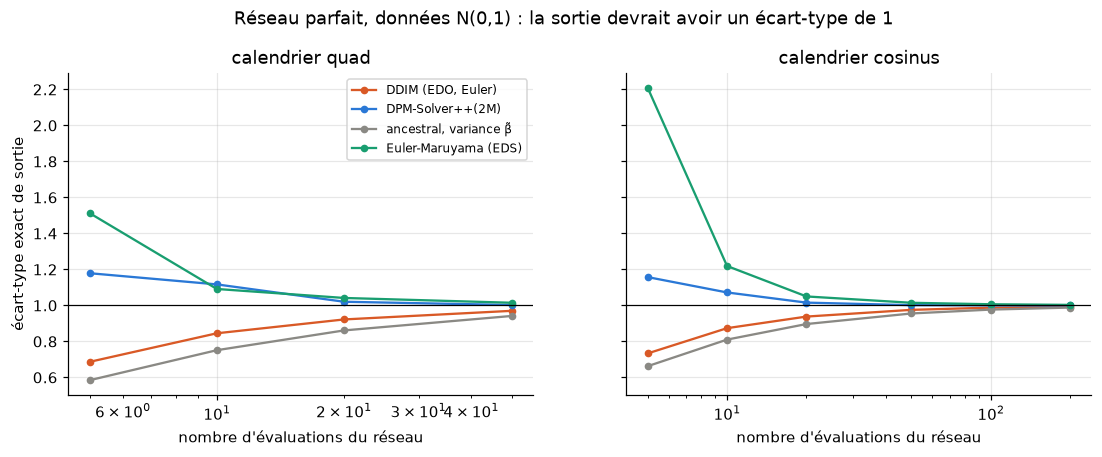

5       10      20      50      100     200
quad    DDIM (EDO, Euler)       0.6865  0.8453  0.9221  0.9702     NaN     NaN
        DPM-Solver++(2M)        1.1790  1.1168  1.0204  1.0023     NaN     NaN
        ancestral, variance β̃  0.5844  0.7513  0.8612  0.9418     NaN     NaN
        Euler-Maruyama (EDS)    1.5128  1.0914  1.0415  1.0147     NaN     NaN
cosinus DDIM (EDO, Euler)       0.7333  0.8736  0.9381  0.9754  0.9877  0.9938
        DPM-Solver++(2M)        1.1575  1.0721  1.0156  1.0015  1.0001  0.9999
        ancestral, variance β̃  0.6623  0.8101  0.8966  0.9554  0.9769  0.9882
        Euler-Maruyama (EDS)    2.2101  1.2191  1.0499  1.0147  1.0065  1.0030

In [20]:
NS = [5, 10, 20, 50, 100, 200]
SAMPLERS = {"ddim": ("DDIM (EDO, Euler)", ORANGE), "dpm2m": ("DPM-Solver++(2M)", BLUE),
            "ancestral": ("ancestral, variance β̃", GREY), "euler_maruyama": ("Euler-Maruyama (EDS)", GREEN)}
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
tab = {}
for a_, (sname, ab) in zip(ax, [("quad", ab_q), ("cosinus", ab_c)]):
    for s, (lab, col) in SAMPLERS.items():
        ns = [n for n in NS if n <= len(ab)]
        sd = [T.gaussian_output_std(ab, s, n) for n in ns]
        a_.plot(ns, sd, "o-", color=col, label=lab, ms=4)
        tab[(sname, lab)] = dict(zip(ns, sd))
    a_.axhline(1, color="k", lw=.8); a_.set_xscale("log"); a_.set_xlabel("nombre d'évaluations du réseau")
    a_.set_title(f"calendrier {sname}")
ax[0].set_ylabel("écart-type exact de sortie"); ax[0].legend(fontsize=8)
fig.suptitle("Réseau parfait, données N(0,1) : la sortie devrait avoir un écart-type de 1", y=1.03); plt.show()
pd.DataFrame(tab).T.round(4)

### Loi à queues épaisses

Débruiteur exact de la loi jouet : la contraction affecte davantage le quantile à 1 % que l'écart-type.

In [21]:
rows = {}
for s in ["ddim", "ancestral", "euler_maruyama"]:
    for n in (10, 50):
        x, _, _ = T.sample(ab_q, s, n, T.mixture_eps, rng.standard_normal(200_000), rng)
        rows[(SAMPLERS[s][0], n)] = {"écart-type": x.std(), "kurtosis": stats.kurtosis(x, fisher=False),
                                     "q1 % / q1 % vrai": np.quantile(x, .01) / -2.72998,
                                     "écart-type, théorie gaussienne": T.gaussian_output_std(ab_q, s, n)}
print("Calendrier quad, vérité : écart-type 1, kurtosis 5,72, q1 % = −2,730")
pd.DataFrame(rows).T

Calendrier quad, vérité : écart-type 1, kurtosis 5,72, q1 % = −2,730


écart-type  kurtosis  q1 % / q1 % vrai  écart-type, théorie gaussienne
DDIM (EDO, Euler)      10      0.8123    5.1934            0.7725                          0.8453
                       50      0.9644    5.6098            0.9626                          0.9702
ancestral, variance β̃ 10      0.6959    4.7987            0.6303                          0.7513
                       50      0.9237    5.6440            0.8928                          0.9418
Euler-Maruyama (EDS)   10      1.1337    4.7688            1.1090                          1.0914
                       50      1.0247    5.4785            1.0177                          1.0147

### Modèle A entraîné

Validation : écart-type relatif des scénarios. DDIM à peu de pas est trop étroit, DPM-Solver++ quasi calibré, dans le sens
prédit. Le schéma est choisi sur la validation.

In [22]:
sv = pd.read_csv(DATA / "panel_I" / "sampler_val.csv")
sv.rename(columns={"nfe": "évaluations", "rel_sd": "écart-type relatif", "crps_fc": "CRPS prévision",
                   "crps_imp": "CRPS imputation", "cov80_fc": "couv. 80 % prév.", "sec_per_1000": "s / 1000 scénarios"})

,sampler,évaluations,CRPS prévision,CRPS imputation,couv. 80 % prév.,cov80_imp,écart-type relatif,s / 1000 scénarios
0,ddim,5,0.6993,0.6478,0.6711,0.6471,0.6283,1.5312
1,ddim,10,0.6890,0.6341,0.7556,0.7422,0.7893,2.5322
2,ddim,20,0.6873,0.6302,0.7924,0.7725,0.8725,4.8037
3,ddim,50,0.6872,0.6285,0.8124,0.7999,0.9230,13.9433
4,dpm2m,5,0.6903,0.6356,0.8413,0.8480,0.9913,1.2874
5,dpm2m,10,0.6916,0.6321,0.8431,0.8372,0.9943,2.7112
6,dpm2m,20,0.6889,0.6292,0.8280,0.8234,0.9642,5.1328
7,ddpm-large,200,0.6860,0.6301,0.8173,0.8145,0.9413,52.6267


## 6. Règles de score

$$
\mathrm{CRPS}(F, y) = \mathbb E_F|X - y| - \tfrac12\,\mathbb E_F|X - X'| .
$$

Strictement propre : espérance minimale pour la vraie loi seulement. Sur un ensemble de $m$ scénarios, l'estimateur
empirique divise la double somme par $m^2$ et favorise les ensembles trop étroits ; l'estimateur équitable divise par
$m(m-1)$ et est sans biais.

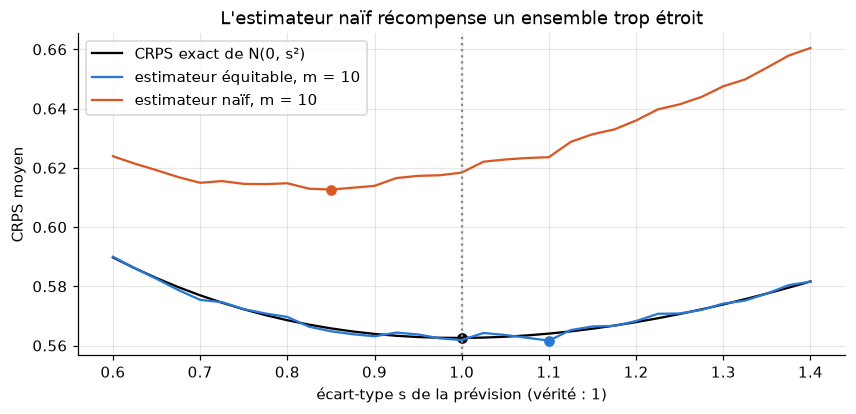

Minimum : exact s = 1.000, équitable s = 1.100, naïf s = 0.850


In [23]:
def crps_ens(ens, y, fair=True):
    # ens : (..., m) ; y : (...)
    m = ens.shape[-1]
    t1 = np.abs(ens - y[..., None]).mean(-1)
    s = np.sort(ens, axis=-1); i = np.arange(1, m + 1)
    pair_sum = 2 * np.sum((2 * i - m - 1) * s, axis=-1)          # Σ_{j,k} |x_j − x_k| en O(m log m)
    return t1 - pair_sum / (2 * (m * (m - 1) if fair else m ** 2))

def crps_gauss(y, sd):
    z = y / sd
    return sd * (z * (2 * stats.norm.cdf(z) - 1) + 2 * stats.norm.pdf(z) - 1 / np.sqrt(np.pi))

m, n_obs = 10, 40_000
y = rng.standard_normal(n_obs)                                   # vérité N(0,1)
sds = np.linspace(.6, 1.4, 33)
exact, naive, fair = [], [], []
for s in sds:
    ens = s * rng.standard_normal((n_obs, m))
    exact.append(crps_gauss(y, s).mean()); naive.append(crps_ens(ens, y, False).mean()); fair.append(crps_ens(ens, y, True).mean())

fig, ax = plt.subplots(figsize=(9, 3.8))
for v, lab, c in [(exact, "CRPS exact de N(0, s²)", "k"), (fair, f"estimateur équitable, m = {m}", BLUE),
                  (naive, f"estimateur naïf, m = {m}", ORANGE)]:
    ax.plot(sds, v, color=c, label=lab); ax.plot(sds[np.argmin(v)], min(v), "o", color=c)
ax.axvline(1, color=GREY, ls=":"); ax.set_xlabel("écart-type s de la prévision (vérité : 1)"); ax.set_ylabel("CRPS moyen")
ax.set_title("L'estimateur naïf récompense un ensemble trop étroit"); ax.legend(); plt.show()
print(f"Minimum : exact s = {sds[np.argmin(exact)]:.3f}, équitable s = {sds[np.argmin(fair)]:.3f}, naïf s = {sds[np.argmin(naive)]:.3f}")

**Sensibilité à l'échelle.** Près de la vraie loi, le CRPS est plat en l'écart-type : quelques % de sous-dispersion le
modifient à peine. Couverture et VaR sont donc rapportées en complément.

Autres critères du projet : energy score, twCRPS, perte FZ0 pour le couple (VaR, ES), tests de Diebold-Mariano.

## 7. Panel I : modèle A contre GARCH

Modèle A : normalisation par fenêtre, prédiction de $v$, DPM-Solver++(2M) à 20 évaluations. Références : simulation
historique (HS), EWMA, GARCH-*t*, GJR-*t*, simulation historique filtrée (FHS). 4 392 origines, horizon 10 jours.

Résultats relus ; les réseaux ne sont pas réentraînés.

In [24]:
ft = pd.read_csv(DATA / "panel_I" / "forecast_table.csv")
cols = ["CRPS_h1", "CRPS_cum10", "twCRPS_h1", "CRPS_RV", "Cov90_h1", "Cov98_h1"]
piv = ft.pivot_table(index="model", columns="index", values=cols).swaplevel(axis=1).sort_index(axis=1)
order = ["HS", "EWMA-N", "GARCH-t", "GJR-t", "FHS", "Diffusion"]
piv.loc[[m for m in order if m in piv.index]].round(4)

index     FTSE100                                                  SP500                                                STOXX50E                              \
          CRPS_RV CRPS_cum10 CRPS_h1 Cov90_h1 Cov98_h1 twCRPS_h1 CRPS_RV CRPS_cum10 CRPS_h1 Cov90_h1 Cov98_h1 twCRPS_h1  CRPS_RV CRPS_cum10 CRPS_h1 Cov90_h1   
model                                                                                                                                                          
HS         0.6287     1.3088  0.4170   0.9203   0.9830    0.0356  0.8831     1.6861  0.5534   0.9062   0.9740    0.0617   0.7976     1.7293  0.5689   0.9139   
EWMA-N     0.6005     1.2768  0.4137   0.8985   0.9659    0.0351  0.6758     1.6327  0.5419   0.8815   0.9719    0.0595   0.7612     1.6821  0.5667   0.8941   
GARCH-t    0.5512     1.2555  0.4104   0.9149   0.9796    0.0345  0.6149     1.5809  0.5368   0.8938   0.9795    0.0596   0.6974     1.6594  0.5606   0.9112   
GJR-t      0.5520     1.2558  0.4119   0.9114   0.9850    0.0348  0.5925     1.5739  0.5340   0.8870   0.9849    0.0590   0.6706     1.6614  0.5583   0.9030   
FHS        0.5349     1.2562  0.4096   0.9019   0.9789    0.0351  0.5977     1.5828  0.5339   0.9041   0.9801    0.0591   0.6662     1.6572  0.5589   0.8982   
Diffusion  0.5181     1.2510  0.4116   0.8903   0.9748    0.0347  0.5685     1.5755  0.5326   0.8993   0.9842    0.0598   0.6132     1.6830  0.5594   0.9064   

index                         
          Cov98_h1 twCRPS_h1  
model                         
HS          0.9836    0.0438  
EWMA-N      0.9645    0.0433  
GARCH-t     0.9788    0.0433  
GJR-t       0.9761    0.0431  
FHS         0.9816    0.0429  
Diffusion   0.9727    0.0429

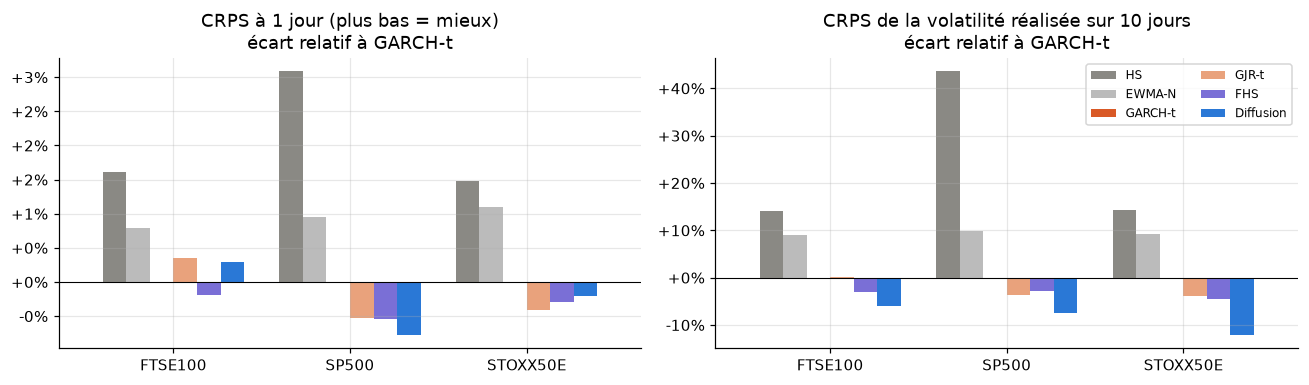

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
sub = ft[ft.model.isin(order)]
for a_, metric, title in [(ax[0], "CRPS_h1", "CRPS à 1 jour (plus bas = mieux)"),
                          (ax[1], "CRPS_RV", "CRPS de la volatilité réalisée sur 10 jours")]:
    p = sub.pivot(index="model", columns="index", values=metric).loc[order]
    rel = p / p.loc["GARCH-t"] - 1
    rel.T.plot.bar(ax=a_, color=[GREY, "#bbb", ORANGE, "#e9a27c", PURPLE, BLUE], width=.8, legend=False)
    a_.axhline(0, color="k", lw=.7); a_.set_title(title + "\nécart relatif à GARCH-t"); a_.set_xlabel("")
    a_.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}")); a_.tick_params(axis="x", rotation=0)
ax[1].legend(fontsize=8, ncol=2); plt.tight_layout(); plt.show()

### Tests de Diebold-Mariano

Statistique négative : diffusion meilleure. Tests significatifs à 5 % sur les scores marginaux (CRPS à un jour, moyen,
cumulé, energy score) contre GARCH-*t*, GJR-*t* et FHS.

In [26]:
dm = pd.read_csv(DATA / "panel_I" / "dm_forecast.csv")
strong = dm[dm.baseline.isin(["GARCH-t", "GJR-t", "FHS"])]
marg = ["crps1", "crps_avg", "crps_cum", "es"]
pv = strong[[f"p_{k}" for k in marg]].values
print(f"Scores marginaux : {pv.size} tests, {np.sum(pv < .05)} significatifs à 5 %.")
print(f"Volatilité réalisée : {np.sum(strong.p_rv < .05)} / {len(strong)} significatifs, "
      f"tous en faveur de la diffusion : {bool((strong.loc[strong.p_rv < .05, 'DM_rv'] < 0).all())}.")
strong.set_index(["index", "baseline"])[[f"DM_{k}" for k in marg] + ["DM_rv", "p_rv"]].round(3)

Scores marginaux : 36 tests, 0 significatifs à 5 %.
Volatilité réalisée : 4 / 9 significatifs, tous en faveur de la diffusion : True.


DM_crps1  DM_crps_avg  DM_crps_cum  DM_es  DM_rv   p_rv
index    baseline                                                         
SP500    GARCH-t     -1.315       -0.058       -0.339 -0.177 -2.123  0.034
         GJR-t       -0.409        0.374        0.110  0.418 -1.144  0.253
         FHS         -0.356       -0.015       -0.488  0.107 -1.370  0.171
STOXX50E GARCH-t     -0.358       -0.537        1.256 -0.992 -4.480  0.000
         GJR-t        0.411        0.127        1.438  0.075 -3.029  0.002
         FHS          0.200        0.430        1.332  0.116 -3.020  0.003
FTSE100  GARCH-t      0.493       -0.135       -0.268 -0.434 -1.799  0.072
         GJR-t       -0.091       -0.875       -0.351 -0.958 -1.719  0.086
         FHS          0.816        0.881       -0.394 -0.414 -0.914  0.361

In [27]:
# Tableau des rencontres : 3 indices × 7 scores = 21 tests de Diebold-Mariano à 5 % par référence
SCORES = ["crps1", "crps_avg", "crps_cum", "es", "tw1", "rv", "wcl"]
rows, wins = [], []
for b in ["HS", "EWMA-N", "GARCH-t", "GJR-t", "FHS"]:
    w = l = n = 0
    for _, r in dm[dm.baseline == b].iterrows():
        for k in SCORES:
            if r[f"p_{k}"] < .05:
                w, l = w + (r[f"DM_{k}"] < 0), l + (r[f"DM_{k}"] > 0)
                if r[f"DM_{k}"] < 0 and b in ("GARCH-t", "GJR-t", "FHS"):
                    wins.append(f"{r['index']} · {b} · {k}")
            else:
                n += 1
    rows.append((b, w, n, l))
board = pd.DataFrame(rows, columns=["référence", "A meilleur (établi)", "non établi", "A moins bon (établi)"]).set_index("référence")
print("Victoires établies contre GARCH-t, GJR-t, FHS :", wins)
ft_ = ft.set_index(["index", "model"]).CRPS_RV
for i in ["SP500", "STOXX50E", "FTSE100"]:
    best = min(ft_[(i, m)] for m in ["HS", "EWMA-N", "GARCH-t", "GJR-t", "FHS"])
    print(f"{i:9s} CRPS de la volatilité réalisée, A face à la meilleure référence : {100 * (ft_[(i, 'Diffusion')] / best - 1):+.1f} %")
board

Victoires établies contre GARCH-t, GJR-t, FHS : ['SP500 · GARCH-t · rv', 'STOXX50E · GARCH-t · rv', 'STOXX50E · GJR-t · rv', 'FTSE100 · GJR-t · wcl', 'STOXX50E · FHS · rv']
SP500     CRPS de la volatilité réalisée, A face à la meilleure référence : -4.1 %
STOXX50E  CRPS de la volatilité réalisée, A face à la meilleure référence : -8.0 %
FTSE100   CRPS de la volatilité réalisée, A face à la meilleure référence : -3.2 %


,A meilleur (établi),non établi,A moins bon (établi)
référence,,,
HS,13,8,0
EWMA-N,12,9,0
GARCH-t,2,19,0
GJR-t,2,19,0
FHS,1,20,0


Contre les règles simples : majorité d'écarts établis en faveur de A. Contre GARCH-*t*, GJR-*t* et FHS : 19 à 20 tests sur
21 non établis ; les cinq écarts établis portent sur la trajectoire (volatilité réalisée : 4 ; pire perte cumulée : 1).
Aucun écart établi en défaveur de A.

**Parité.** Aucun des 36 tests sur les quatre scores marginaux n'est significatif.

### Régimes de volatilité et faits stylisés

In [28]:
reg = pd.read_csv(DATA / "panel_I" / "forecast_by_regime.csv")
display(reg.set_index(["index", "regime"]).round(4))
fid = pd.read_csv(DATA / "panel_I" / "fidelity_table.csv")
fid.columns = [c.replace("$", "").replace("\\", "") for c in fid.columns]
fid["Index"] = fid["Index"].str.replace("\\", "", regex=False); fid["Source"] = fid["Source"].str.replace("$", "", regex=False)
fid

HS  EWMA-N  GARCH-t   GJR-t     FHS  Diffusion
index    regime                                                       
SP500    calm       0.3932  0.3723   0.3700  0.3685  0.3682     0.3643
         medium     0.4777  0.4787   0.4722  0.4715  0.4698     0.4664
         turbulent  0.7891  0.7746   0.7681  0.7617  0.7634     0.7671
STOXX50E calm       0.4600  0.4528   0.4479  0.4466  0.4478     0.4465
         medium     0.4904  0.4912   0.4822  0.4861  0.4836     0.4874
         turbulent  0.7563  0.7563   0.7516  0.7421  0.7453     0.7444
FTSE100  calm       0.3503  0.3424   0.3453  0.3430  0.3442     0.3479
         medium     0.3678  0.3624   0.3623  0.3607  0.3584     0.3598
         turbulent  0.5330  0.5363   0.5238  0.5321  0.5264     0.5274

,Index,Source,Kurt.,Kurt. (std.),Skew. (std.),"ACF |r|, lag 1","ACF |r|, lags 1--5","ACF r, lag 1",Leverage
0,S&P 500,Real (test),9.2,3.99,-0.16,0.016,0.041,-0.020,-0.107
1,S&P 500,Diffusion,11.5,4.16,-0.21,0.047,0.050,-0.063,-0.095
2,S&P 500,GARCH-t,27.1,4.30,-0.01,0.070,0.052,-0.021,-0.006
3,S&P 500,GJR-t,19.5,4.85,0.30,0.093,0.067,-0.018,-0.054
4,Euro Stoxx 50,Real (test),6.8,4.09,-0.19,0.087,0.041,-0.081,-0.120
5,Euro Stoxx 50,Diffusion,9.1,3.87,-0.06,0.033,0.037,-0.033,-0.108
6,Euro Stoxx 50,GARCH-t,12.1,3.75,-0.00,0.047,0.034,-0.020,0.000
7,Euro Stoxx 50,GJR-t,13.0,4.02,0.19,0.055,0.042,-0.032,-0.053
8,FTSE 100,Real (test),7.7,4.43,-0.27,0.101,0.034,-0.037,-0.090
9,FTSE 100,Diffusion,8.6,3.77,-0.11,0.036,0.038,-0.018,-0.106


Effet de levier des scénarios de A : −0,095 sur le S&P 500, contre −0,107 dans les données et −0,006 pour GARCH-*t*
(symétrique par construction). Dans les tiers les plus volatils, un modèle paramétrique est meilleur.

### VaR à 1 % et 5 % : Kupiec et Christoffersen

In [29]:
var = pd.read_csv(DATA / "panel_I" / "var_table.csv")
v = var[var.model.isin(order)].copy()
v["attendus"] = (v.n * v.alpha).round(1)
v.pivot_table(index=["index", "model"], columns="alpha", values=["hits", "attendus", "p_cc"]).round(3).loc[
    [(i, m) for i in INDICES for m in order]]

attendus        hits          p_cc       
alpha                  0.01  0.05  0.01   0.05   0.01   0.05
index    model                                              
SP500    HS            14.6  73.0  18.0   68.0  0.322  0.269
         EWMA-N        14.6  73.0  28.0   93.0  0.006  0.065
         GARCH-t       14.6  73.0  25.0   98.0  0.034  0.009
         GJR-t         14.6  73.0  17.0  101.0  0.677  0.004
         FHS           14.6  73.0  14.0   67.0  0.862  0.655
         Diffusion     14.6  73.0  11.0   74.0  0.117  0.789
STOXX50E HS            14.6  73.2   8.0   65.0  0.000  0.005
         EWMA-N        14.6  73.2  31.0   82.0  0.000  0.468
         GARCH-t       14.6  73.2  19.0   72.0  0.279  0.959
         GJR-t         14.6  73.2  21.0   83.0  0.173  0.296
         FHS           14.6  73.2  13.0   71.0  0.239  0.079
         Diffusion     14.6  73.2  22.0   63.0  0.003  0.450
FTSE100  HS            14.7  73.4  13.0   59.0  0.237  0.000
         EWMA-N        14.7  73.4  29.0   78.0  0.000  0.028
         GARCH-t       14.7  73.4  18.0   69.0  0.561  0.001
         GJR-t         14.7  73.4  14.0   78.0  0.860  0.003
         FHS           14.7  73.4  14.0   67.0  0.296  0.002
         Diffusion     14.7  73.4  17.0   69.0  0.000  0.005

### Imputation

Rendements cachés au hasard (10 % ou 30 %) ou par blocs (5 ou 20 jours). Références : interpolation linéaire, ponts
browniens (EWMA, volatilité locale), lisseur GJR-*t*.

In [30]:
imp = pd.read_csv(DATA / "panel_I" / "imputation_pooled.csv")
p = imp.pivot(index="model", columns="scenario", values="CRPS").loc[["Linear", "BB-EWMA", "BB-local", "GJR-t", "Diffusion"]]
display(p.round(4))
dmi = pd.read_csv(DATA / "panel_I" / "dm_imputation.csv")
w = dmi[dmi.baseline == "GJR-t"] if "GJR-t" in set(dmi.baseline) else dmi
print("Diffusion contre", w.baseline.unique(), ":", (w.p < .05).sum(), "tests significatifs sur", len(w))

scenario,block-20,block-5,random-10%,random-30%
model,,,,
Linear,0.6964,0.6440,0.5100,0.5327
BB-EWMA,0.5194,0.4834,0.3795,0.3965
BB-local,0.5140,0.4781,0.3740,0.3896
GJR-t,0.5104,0.4661,0.3669,0.3840
Diffusion,0.5111,0.4726,0.3661,0.3858


Diffusion contre <ArrowStringArray>
['GJR-t']
Length: 1, dtype: str : 1 tests significatifs sur 12


### Ablation et données simulées

Un composant retiré à la fois (validation). Prédire $\varepsilon$ au lieu de $v$ : CRPS presque doublé.

In [31]:
abl = pd.read_csv(DATA / "panel_I" / "ablation.csv")
display(abl.round(4))
display(pd.read_csv(DATA / "panel_I" / "synthetic_forecast.csv").round(4))
si = pd.read_csv(DATA / "panel_I" / "synthetic_imputation.csv").set_index("model")
print("Imputation, écart de CRPS à l'oracle (%) :", (100 * (si["all"] / si.loc[si.index.str.startswith("Oracle"), "all"].iloc[0] - 1)).round(2).to_dict())

,variant,crps_fc,crps_imp,cov80_fc,cov80_imp,t_fc,t_imp,best_it
0,main,0.6911,0.6180,0.8237,0.7990,NaN,NaN,1750.0
1,global-norm,0.6943,0.6210,0.8330,0.8106,0.9642,1.0796,1250.0
2,eps-param,1.3214,1.0575,0.9287,0.9202,9.9236,6.5057,4000.0
3,no-covariates,0.6996,0.6240,0.8173,0.8022,4.1109,1.9914,2750.0
4,no-attention,0.6964,0.6239,0.8190,0.7889,1.6208,1.6407,2000.0
5,no-regularisation,0.6996,0.6222,0.8117,0.7939,2.3164,1.1604,2000.0
6,ensemble,0.6925,0.6249,0.8227,0.7947,0.4010,1.1961,NaN
7,seed-1,0.6935,0.6212,0.8200,0.7934,1.3167,1.4264,NaN
8,seed-2,0.6942,0.6224,0.8177,0.7961,1.4012,1.7511,NaN


,model,CRPS_h1,CRPS_avg,CRPS_cum10,Energy,twCRPS_h1,CRPS_RV,Cov90_h1,gap
0,HS,0.5175,0.5202,1.6986,2.0639,0.0862,0.9106,0.8927,3.4339
1,EWMA-N,0.5013,0.5063,1.6426,2.0004,0.0812,0.6458,0.8914,0.6608
2,GARCH-t,0.5008,0.5029,1.6270,1.9879,0.0805,0.5792,0.8975,-0.0102
3,GJR-t,0.4965,0.5031,1.6284,1.9882,0.0804,0.5742,0.9070,0.0311
4,FHS,0.5001,0.5037,1.6395,1.9912,0.0808,0.5820,0.9016,0.1498
5,Diffusion,0.5028,0.5076,1.6313,2.0057,0.0815,0.6551,0.9117,0.9267
6,Oracle,0.5006,0.5030,1.6327,1.9887,0.0810,0.5744,0.9043,0.0000


Imputation, écart de CRPS à l'oracle (%) : {'Linear': 38.52, 'BB-EWMA': 4.06, 'BB-local': 1.23, 'GJR-t': -0.29, 'Diffusion': 0.85, 'Oracle': 0.0}


Données simulées par un GARCH connu : la colonne `gap` donne l'écart de CRPS à l'oracle. Le modèle A paie environ 1 % ; sur
données réelles il est à égalité avec les GARCH, ce qui indique une structure que le GARCH ne décrit pas.

## 8. Panel II : modèle B et loi jointe

Le modèle B génère conjointement les huit actifs. 135 fenêtres hebdomadaires, horizon 5 jours, 100 scénarios, trois
entraînements.

### Prévision

In [32]:
fc = js("panel_II/forecast_test")
LAB = {"naive": "Naïve", "garch": "GARCH", "deepar": "DeepAR", "csdi": "Modèle B (CSDI)"}
summ = pd.DataFrame({LAB[k]: {m: fc["summary"][k][m][0] for m in ["crps", "crps_sum", "mae", "coverage_90", "width_90"]}
                     for k in LAB}).T
display(summ.round(4))
stt = js("panel_II/statistics_test")["tasks"]["prévision"]["comparisons"]
print("Écart de CRPS modèle B − concurrent (bootstrap hiérarchique : blocs de 4 semaines et entraînements) :")
for k in ("naive", "garch", "deepar"):
    d = stt[k]["hierarchical"]
    print(f"  B − {LAB[k]:7s} = {d['mean']:+.4f}   IC 95 % [{d['low']:+.4f} ; {d['high']:+.4f}]   établi : {d['significant']}")
print(f"Couverture 90 % du modèle B : {summ.loc['Modèle B (CSDI)', 'coverage_90']:.3f} "
      f"(prédiction de la théorie, calendrier quad : {DEF.iloc[0, -1]:.3f})")

,crps,crps_sum,mae,coverage_90,width_90
Naïve,0.5278,1.8080,0.7153,0.8754,2.9506
GARCH,0.5158,1.7528,0.7049,0.8846,2.8759
DeepAR,0.5145,1.7468,0.7057,0.8778,2.8152
Modèle B (CSDI),0.5206,1.7737,0.7065,0.8649,2.7710


Écart de CRPS modèle B − concurrent (bootstrap hiérarchique : blocs de 4 semaines et entraînements) :
  B − Naïve   = -0.0072   IC 95 % [-0.0132 ; -0.0022]   établi : True
  B − GARCH   = +0.0048   IC 95 % [+0.0015 ; +0.0083]   établi : True
  B − DeepAR  = +0.0061   IC 95 % [+0.0025 ; +0.0103]   établi : True
Couverture 90 % du modèle B : 0.865 (prédiction de la théorie, calendrier quad : 0.879)


Le modèle B fait moins bien que GARCH et sous-couvre, dans le sens et l'ordre de grandeur prédits par le théorème 5.5 pour
le calendrier quad.

### Imputation et prix manquants

Un prix manquant fixe la somme des rendements du trou (écart des log-prix aux bords). Le krigeage gaussien multivarié
exploite cette contrainte et les autres marchés du même jour.

In [33]:
# L'écart B − GARCH s'explique-t-il par le schéma ? Proposition 7.5 : E CRPS(N(0, c²)) / E CRPS(N(0, 1)) = √(2(1+c²)) − c
from scipy.optimize import brentq
gap = 100 * (fc["summary"]["csdi"]["crps"][0] / fc["summary"]["garch"]["crps"][0] - 1)
excess = lambda c: 100 * (np.sqrt(2 * (1 + c ** 2)) - c - 1)
sB = T.gaussian_output_std(T.quad_schedule(), "ddpm")
c_need = brentq(lambda c: excess(c) - gap, 0.5, 1.0)
print(f"Écart observé B − GARCH : {gap:.2f} % de CRPS")
print(f"Part du schéma de B (écart-type {sB:.3f}) : {excess(sB):.2f} %")
print(f"Erreur d'échelle qu'il faudrait pour l'expliquer seule : {100 * (1 - c_need):.0f} % (c = {c_need:.3f})")

Écart observé B − GARCH : 0.93 % de CRPS
Part du schéma de B (écart-type 0.942) : 0.09 %
Erreur d'échelle qu'il faudrait pour l'expliquer seule : 18 % (c = 0.816)


Le schéma de B rétrécit la loi de 6 %, soit 0,09 % de CRPS ; l'écart de 0,93 % exigerait une contraction d'environ 18 %.
Le défaut de score a une autre cause (§ 10).

In [34]:
ip = js("panel_II/imputation_probabiliste_test")["results"]
print("Rendements manquants : écart de CRPS modèle B − méthode (négatif : B meilleur), IC 95 %")
rows = {}
for task, lab in (("points", "points isolés"), ("blocks", "blocs de 5 jours")):
    for meth, v in ip[task].items():
        d = v["csdi_minus_method"]["crps"]
        rows[(lab, meth)] = {"CRPS méthode": v["crps"], "B − méthode": d["mean"], "bas": d["low"], "haut": d["high"],
                             "établi": d["low"] > 0 or d["high"] < 0}
display(pd.DataFrame(rows).T)

Rendements manquants : écart de CRPS modèle B − méthode (négatif : B meilleur), IC 95 %


CRPS méthode B − méthode     bas    haut établi
points isolés    pont_brownien              0.5122     -0.0313 -0.0426 -0.0222   True
                 ewma_univarie              0.5161     -0.0353 -0.0439 -0.0282   True
                 ewma_multivarie            0.4727      0.0081 -0.0004  0.0184  False
                 lisseur_particulaire        0.506     -0.0252 -0.0343 -0.0179   True
blocs de 5 jours pont_brownien              0.5162      -0.026 -0.0371 -0.0172   True
                 ewma_univarie              0.5193     -0.0291  -0.037 -0.0231   True
                 ewma_multivarie            0.4854      0.0048  -0.005  0.0152  False
                 lisseur_particulaire       0.5104     -0.0202 -0.0282  -0.014   True

In [35]:
# Prix manquants : une échelle d'information. Plus une méthode exploite d'information, plus son CRPS baisse.
INFO = {"knn": "passé", "interpolation_log_prix": "somme", "knn_krigeage": "passé + somme",
        "ewma_multivarie": "même jour", "pont_ewma": "passé + somme", "pont_local": "après + somme",
        "lisseur_gjr": "passé + après + somme", "ewma_contrainte": "même jour + somme"}
res = js("panel_II/imputation_prix_test")["results"]
cmp_ = js("panel_II/imputation_prix_test_comparaisons")
pd.DataFrame({k: {"information utilisée": INFO[k], "CRPS": res[k]["crps"], "couverture 90 %": res[k].get("coverage_90"),
                  "écart à la meilleure [IC 95 %]": (f"+{cmp_[k]['crps']['mean']:.4f} [{cmp_[k]['crps']['low']:.4f} ; "
                                                     f"{cmp_[k]['crps']['high']:.4f}]" if k in cmp_ else "référence")}
              for k in INFO}).T.sort_values("CRPS", ascending=False)

,information utilisée,CRPS,couverture 90 %,écart à la meilleure [IC 95 %]
knn,passé,0.6828,0.0,+0.2800 [0.2577 ; 0.3064]
interpolation_log_prix,somme,0.5876,0.0,+0.1848 [0.1651 ; 0.2085]
knn_krigeage,passé + somme,0.5863,0.0,+0.1835 [0.1656 ; 0.2047]
ewma_multivarie,même jour,0.4722,0.8743,+0.0694 [0.0645 ; 0.0751]
pont_local,après + somme,0.4338,0.8829,+0.0310 [0.0194 ; 0.0445]
pont_ewma,passé + somme,0.4321,0.9003,+0.0293 [0.0184 ; 0.0422]
lisseur_gjr,passé + après + somme,0.4268,0.8863,+0.0240 [0.0133 ; 0.0370]
ewma_contrainte,même jour + somme,0.4028,0.8653,référence


### Interprétabilité du modèle B

Trois expériences du rapport (§ 13.4), sur le premier entraînement. Elles demandent le réseau et ne sont pas refaites ici ;
les valeurs sont reprises du rapport.

**Huit actifs contre un** (test). Prévision : CRPS ; imputation : erreur absolue moyenne.

| Actif | Tâche | 8 actifs | 1 actif | 8 − 1, IC à 95 % |
|---|---|---:|---:|---|
| Euro Stoxx 50 | prévision | 0,4090 | 0,4115 | −0,0016 [−0,0089 ; +0,0063] |
| | imputation, points | 0,4288 | 0,5683 | −0,1480 [−0,1872 ; −0,1156] |
| Nikkei 225 | prévision | 0,6683 | 0,6640 | +0,0056 [−0,0015 ; +0,0145] |
| | imputation, points | 0,8416 | 0,8728 | −0,0307 [−0,0601 ; −0,0087] |

**Masquage** (validation, même réseau). Erreur absolue d'imputation de l'Euro Stoxx 50 : 0,433 avec toute l'information,
0,733 sans les autres marchés du même jour, 0,751 sans aucun autre marché. Le même jour porte 94 % de l'apport des autres
marchés, le FTSE 100 seul les deux tiers.

**Permutation de l'historique** (test, 68 fenêtres). Bruit de simulation : 0,0086 par actif. Seul effet au-dessus : le Brent
sur sa propre prévision (+0,0217). Effets croisés : au plus +0,0016 en moyenne.

Les autres marchés servent à compléter une case, pas à prévoir, ce que les corrélations du § 1 laissaient attendre.

### Vérification de l'implémentation : Exchange Rate

CSDI entraîné avec les réglages publiés par ProbTS (contexte 30 jours, 4 couches de 64 canaux, quad à 50 niveaux,
100 scénarios), trois entraînements.

| | CRPS | NMAE |
|---|---:|---:|
| Notre implémentation | 0,0084 ± 0,0008 | 0,0113 ± 0,0011 |
| ProbTS, publié | 0,008 | 0,011 |

### Loi jointe : mêmes marges, VaR opposées

GJR (marchés indépendants) et GJR-CCC (copule gaussienne de corrélation $R$) ont les mêmes lois marginales ; seule la
dépendance du même jour diffère. Aucun score marginal ne les distingue ; la VaR d'un portefeuille équipondéré, si :

$$
\operatorname{Var}\Big(\tfrac1D\sum_d z_d\Big) = \frac{1}{D^2}\sum_{d,e} R_{de}.
$$

In [36]:
lj = js("panel_II/loi_jointe_test")["methods"]
rows = {}
for k, mth in lj.items():
    for a in ("0.01", "0.05"):
        od = mth["var"][a]["one_day"]
        rows[(mth["label"], a)] = {"dépassements": od["kupiec"]["hits"], "attendus": od["kupiec"]["expected"],
                                   "p Kupiec": od["kupiec"]["p_value"], "p Christoffersen": od["christoffersen"]["p_value"]}
pd.DataFrame(rows).T.round(4)

dépassements  attendus  p Kupiec  p Christoffersen
Naïve                       0.01          24.0      6.75    0.0000            0.0001
                            0.05          53.0     33.75    0.0016            0.0018
GARCH(1,1) Student          0.01          17.0      6.75    0.0009            0.0004
                            0.05          53.0     33.75    0.0016            0.0223
GJR-GARCH(1,1) Student      0.01          19.0      6.75    0.0001            0.0012
                            0.05          48.0     33.75    0.0176            0.0053
GJR-CCC (copule gaussienne) 0.01           6.0      6.75    0.7675            0.0000
                            0.05          25.0     33.75    0.1059            0.0001

**Contrôle sur les scénarios bruts** (300 scénarios × 135 fenêtres × 8 actifs × 5 jours). Écarts-types par actif
identiques, écarts-types du portefeuille différents.

In [37]:
load = lambda m: np.concatenate([np.load(DATA / "panel_II" / f"prevision_test_{m}_seed{s}.npz")["samples"].astype(float)
                                 for s in range(3)])
S_gjr, S_ccc = load("gjr"), load("ccc")
print("forme des scénarios (scénario, fenêtre, actif, jour) :", S_gjr.shape)
marg = pd.DataFrame({"GJR indépendants": S_gjr.std(axis=(0, 1, 3)), "GJR-CCC": S_ccc.std(axis=(0, 1, 3))}, index=ASSETS_II)
display(marg.T.round(3))
port = lambda S: S.mean(axis=2)
print(f"Écart-type du portefeuille : indépendants {port(S_gjr).std():.3f}  |  CCC {port(S_ccc).std():.3f}  "
      f"→ rapport {port(S_ccc).std() / port(S_gjr).std():.2f}")

Rm = np.array(js("panel_II/forecast_ccc_test")["correlation"]); one = np.ones(8)
print(f"Théorie : √(1ᵀR1)/√8 = {np.sqrt(one @ Rm @ one) / np.sqrt(8):.2f}")

forme des scénarios (scénario, fenêtre, actif, jour) : (300, 135, 8, 5)


,S&P 500,Euro Stoxx 50,FTSE 100,Nikkei 225,Or,Brent,EUR/USD,Oblig. US
GJR indépendants,0.921,0.823,0.796,1.233,1.315,1.167,0.817,0.970
GJR-CCC,0.918,0.826,0.791,1.224,1.354,1.161,0.819,0.974


Écart-type du portefeuille : indépendants 0.362  |  CCC 0.451  → rapport 1.25
Théorie : √(1ᵀR1)/√8 = 1.31


Si l'on calcule la VaR 1 % en supposant les marchés indépendants, le vrai portefeuille la dépasse 3.3% du temps au lieu de 1 %.


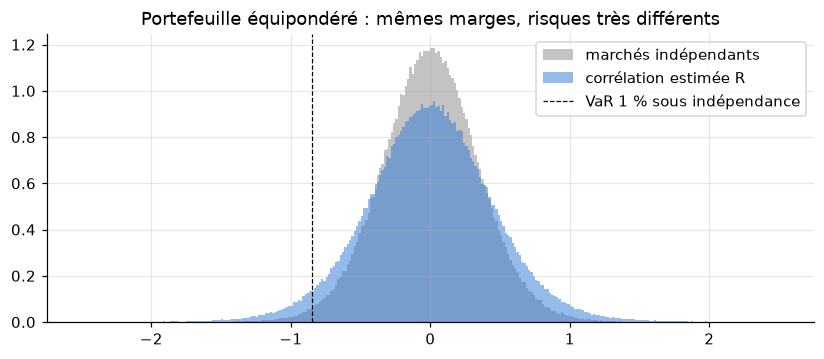

In [38]:
# Simulation : marges de Student identiques, seule la corrélation change
nu, n = 5.0, 400_000
to_t = lambda u: np.sqrt((nu - 2) / nu) * stats.t.ppf(stats.norm.cdf(u), nu)
g_c = rng.standard_normal((n, 8)) @ np.linalg.cholesky(Rm).T
p_c, p_i = to_t(g_c).mean(1), to_t(rng.standard_normal((n, 8))).mean(1)
v_i = np.quantile(p_i, .01)
print(f"Si l'on calcule la VaR 1 % en supposant les marchés indépendants, le vrai portefeuille la dépasse "
      f"{np.mean(p_c < v_i):.1%} du temps au lieu de 1 %.")
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.hist(p_i, bins=300, range=(-2.5, 2.5), density=True, alpha=.5, color=GREY, label="marchés indépendants")
ax.hist(p_c, bins=300, range=(-2.5, 2.5), density=True, alpha=.5, color=BLUE, label="corrélation estimée R")
ax.axvline(v_i, color="k", ls="--", lw=.8, label="VaR 1 % sous indépendance")
ax.set_title("Portefeuille équipondéré : mêmes marges, risques très différents"); ax.legend(); plt.show()

Test : 19 dépassements de la VaR à 1 % pour le modèle indépendant, 6 pour GJR-CCC, 6,75 attendus. À marges identiques,
l'un est dépassé 2,8 fois trop souvent, l'autre au niveau nominal. Les scores marginaux ne mesurent pas la loi jointe.

## 9. Coût de calcul

Comptage à partir des architectures (rapport, section 12.3), vérification des deux hypothèses, comparaison aux temps
chronométrés.

$$C_{\text{scénario}}=\mathrm{NFE}\times\Big(2PN+\sum_{\text{attentions}}4n^2d\Big)$$

$P$ paramètres, $N$ positions, NFE évaluations ; une multiplication-addition compte pour deux opérations.

In [39]:
import calcul as K                       # le même module que le démonstrateur

# Hypothèse 1 : la largeur C du modèle A, que le rapport ne donne pas, est bornée par ses 146 401 paramètres
Cs = np.arange(32, 65)
print(f"Largeur maximale compatible avec 146 401 paramètres : C = {K.WIDTH_MAX_A} "
      f"(C = {K.WIDTH_MAX_A + 1} exigerait au moins {K.width_floor_params(K.WIDTH_MAX_A + 1):,} paramètres)")
cout = pd.DataFrame({m: {"P": K.MODELS[m]["P"], "N": K.MODELS[m]["N"], "2PN": K.per_eval(m)["dense"],
                         "attention": K.per_eval(m)["attention"], "par évaluation": K.per_eval(m)["total"],
                         "NFE": K.MODELS[m]["nfe"], "par scénario": K.per_scenario(m)} for m in "AB"}).T
lo, hi = K.per_scenario("A", d=32), K.per_scenario("A", d=K.WIDTH_MAX_A)
print(f"Modèle A : {lo:.3g} à {hi:.3g} opérations par scénario selon la largeur ({100 * (hi / lo - 1):.1f} % d'écart)")
cout

Largeur maximale compatible avec 146 401 paramètres : C = 57 (C = 58 exigerait au moins 149,408 paramètres)
Modèle A : 3.85e+08 à 3.93e+08 opérations par scénario selon la largeur (2.1 % d'écart)


,P,N,2PN,attention,par évaluation,NFE,par scénario
A,146401.0,64.0,1.8739e+07,9.3389e+05,1.9673e+07,20.0,3.9346e+08
B,430017.0,520.0,4.4722e+08,3.8871e+07,4.8609e+08,50.0,2.4304e+10


In [40]:
# Hypothèse 2 : le coût d'un tirage aléatoire, en équivalent de multiplications ou additions élémentaires
dc = K.measure_draw_costs()
print({k: round(v, 1) for k, v in dc.items()}, "→ conventions retenues :", K.DRAW)
G = K.ref_per_scenario("GJR-t")
print(f"GJR-t : ≈ {G:.0f} opérations par scénario de 10 jours ; modèle A / GJR-t ≈ {K.per_scenario('A') / G:.2g}")
pd.DataFrame([(k, v[0], v[1], 10 * v[1]) for k, v in K.REF_OPS_PER_STEP.items()],
             columns=["méthode", "à chaque jour", "opérations / jour", "pour 10 jours"]).set_index("méthode")

{'normal': 21.9, 'student': 69.4, 'index': 10.7} → conventions retenues : {'normal': 20, 'student': 70, 'index': 10}
GJR-t : ≈ 790 opérations par scénario de 10 jours ; modèle A / GJR-t ≈ 5e+05


,à chaque jour,opérations / jour,pour 10 jours
méthode,,,
HS,tirage d'un rendement passé,10,100
EWMA-N,"tirage normal, mise à l'échelle, mise à jour d...",25,250
GARCH-t,"tirage de Student, racine, mise à l'échelle, r...",77,770
GJR-t,"GARCH-t, plus indicatrice de baisse",79,790
FHS,"tirage d'un résidu passé, récurrence GJR",19,190


264 ms par évaluation et par millier de scénarios, R² = 0.9996
Débit effectif implicite : 77 GFLOP/s ; campagne de prévision du test : 37 min


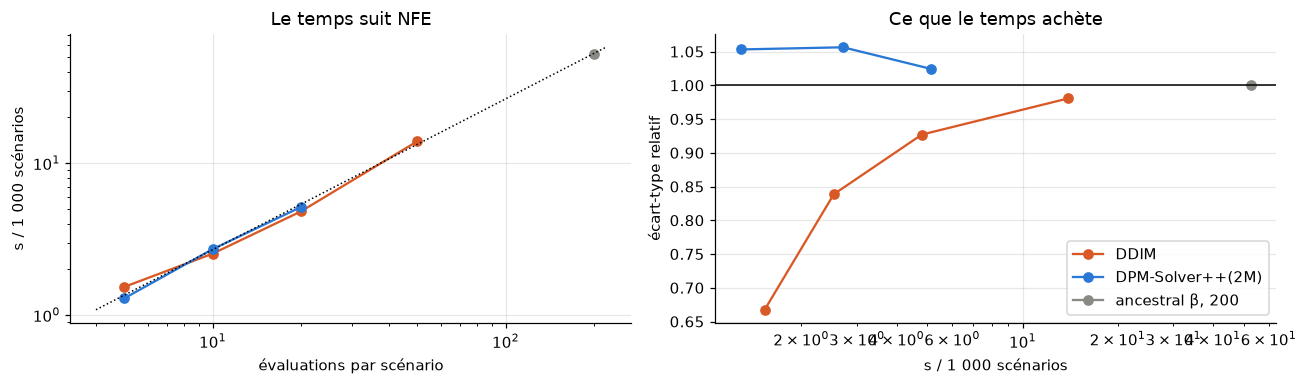

In [41]:
# Temps chronométrés pendant l'étude (validation du panel I) : le temps est-il proportionnel à NFE ?
sv = pd.read_csv(DATA / "panel_I" / "sampler_val.csv")
fit = np.polyfit(sv.nfe, sv.sec_per_1000, 1)
res = sv.sec_per_1000 - np.polyval(fit, sv.nfe)
r2 = 1 - (res ** 2).sum() / ((sv.sec_per_1000 - sv.sec_per_1000.mean()) ** 2).sum()
t20 = sv[(sv.sampler == "dpm2m") & (sv.nfe == 20)].sec_per_1000.iloc[0] / 1000
print(f"{1000 * fit[0]:.0f} ms par évaluation et par millier de scénarios, R² = {r2:.4f}")
print(f"Débit effectif implicite : {K.per_scenario('A') / t20 / 1e9:.0f} GFLOP/s ; "
      f"campagne de prévision du test : {K.CAMPAIGNS['A_prev']['scenarios'] * t20 / 60:.0f} min")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ref = sv[sv.sampler == "ddpm-large"].rel_sd.iloc[0]
for s, lab, col in (("ddim", "DDIM", ORANGE), ("dpm2m", "DPM-Solver++(2M)", BLUE), ("ddpm-large", "ancestral β, 200", GREY)):
    d = sv[sv.sampler == s]
    ax[0].loglog(d.nfe, d.sec_per_1000, "o-", color=col, label=lab)
    ax[1].semilogx(d.sec_per_1000, d.rel_sd / ref, "o-", color=col, label=lab)
nn = np.array([4, 220]); ax[0].loglog(nn, np.polyval(fit, nn), ":", color="k", lw=1)
ax[0].set(xlabel="évaluations par scénario", ylabel="s / 1 000 scénarios", title="Le temps suit NFE")
ax[1].axhline(1, color="k", lw=1); ax[1].set(xlabel="s / 1 000 scénarios", ylabel="écart-type relatif",
                                              title="Ce que le temps achète"); ax[1].legend()
plt.tight_layout(); plt.show()

In [42]:
# Campagnes du test, et mesure en direct sur cette machine
camp = pd.DataFrame({k: {"scénarios": v["scenarios"], "opérations": v["scenarios"] * K.per_scenario(v["model"])}
                     for k, v in K.CAMPAIGNS.items()}).T
camp.loc["GJR_prev"] = [K.CAMPAIGNS["A_prev"]["scenarios"], K.CAMPAIGNS["A_prev"]["scenarios"] * G]
gf = K.measure_matmul_gflops(); sec, n = K.measure_gjr_campaign()
lower = K.CAMPAIGNS["A_prev"]["scenarios"] * K.per_scenario("A") / (gf * 1e9)
print(f"Produit matriciel : {gf:.0f} GFLOP/s. Campagne GJR-t simulée ({n:,} scénarios) : {sec:.2f} s. "
      f"Modèle A, borne basse au débit crête : {lower:.0f} s (au moins {lower / sec:.0f} fois plus).")
camp

Produit matriciel : 1530 GFLOP/s. Campagne GJR-t simulée (434,808 scénarios) : 0.14 s. Modèle A, borne basse au débit crête : 112 s (au moins 816 fois plus).


,scénarios,opérations
A_prev,434808.0,1.7108e+14
A_imp,104544.0,4.1134e+13
B_prev,40500.0,9.8433e+14
B_imp,81000.0,1.9687e+15
GJR_prev,434808.0,3.4350e+08


| Repère | Constat |
|---|---|
| Hypothèse 1 | largeur du modèle A au plus 57 ; incertitude de 2 % sur le coût |
| Hypothèse 2 | tirage de Student ≈ 70 opérations ; scénario GJR-*t* ≈ 8·10² opérations |
| Rapport A / GJR-*t* | ≈ 5·10⁵ par scénario |
| Temps mesurés | affines en NFE ($R^2 > 0{,}999$) ; le comptage ordonne les coûts sans prédire les durées |
| Calibration | DPM-Solver++(2M) à 20 pas : 10,3 fois moins cher que la référence à 200 pas, à 2,4 % de son écart-type |

## 10. Synthèse

| Élément | Résultat | § |
|---|---|---|
| Données | queues épaisses, regroupement de volatilité, effet de levier, dépendance forte le même jour et faible d'un jour sur l'autre | 1 |
| Référence | GARCH-*t* et GJR-*t* réestimés ; paramètres et CRPS retrouvés | 2 |
| Théorie | déficit de la règle d'origine en forme fermée (11,3 % quad, 2,4 % cosinus) ; DDIM contracte, Euler-Maruyama dilate | 5 |
| Évaluation | l'estimateur empirique du CRPS favorise les ensembles trop étroits ; CRPS plat en l'échelle | 6 |
| Modèle A | parité avec GARCH-*t*, GJR-*t* et FHS (0 test significatif sur 36) ; meilleur sur la trajectoire et l'effet de levier | 7 |
| Modèle B | inférieur à GARCH ; sous-couverture dans le sens prédit ; CSDI vérifié sur Exchange Rate | 8 |
| Imputation | A bat l'interpolation et les ponts, égale le lisseur GJR-*t* ; B bat les méthodes univariées, pas l'EWMA multivarié | 7, 8 |
| Interprétabilité | les autres marchés servent au modèle B à compléter, pas à prévoir | 8 |
| Loi jointe | mêmes marges ; VaR de portefeuille dépassée 19 fois contre 6 (6,75 attendus) | 8 |
| Coût | ≈ 3,9·10⁸ opérations par scénario pour A, ≈ 8·10² pour un GJR-*t* | 9 |

### Écart entre les modèles A et B

Panel, horizon, réseau et trois choix de construction diffèrent ; aucun effet n'est isolé. Deux défauts se séparent :

1. **Calibration, expliquée par le schéma.** La règle d'origine de B perd 5,8 % d'écart-type avec un réseau parfait (§ 5) ;
   B couvre 86,5 %, un à deux points sous les références. Le schéma de A est quasi exact.
2. **Score, non expliqué par le schéma.** 6 % de sous-dispersion coûtent 0,09 % de CRPS, contre 0,93 % observés. Cause la
   plus plausible : l'absence d'information de niveau ; sans covariables de niveau, A perd 1,2 % ($t = 4{,}1$).
3. **Paramétrisation.** Prédire $\varepsilon$ dégrade A avec un solveur à 20 pas (+91 %, § 7) ; B parcourt ses 50 niveaux
   avec la règle ancestrale et n'est pas affecté.

Ces explications restent des hypothèses pour B : il faudrait le réentraîner avec l'échelle par fenêtre et les covariables de
niveau, puis le générer avec un schéma fidèle.

**Conclusion.** Un modèle de diffusion bien construit égale les meilleurs GARCH sur des rendements quotidiens et reproduit
mieux la dynamique des trajectoires, pour un calcul environ 5·10⁵ fois plus lourd par scénario. Calendrier, schéma et
nombre de pas pèsent autant que le réseau.